<div style="background:linear-gradient(120deg,#1b3a2f 0%,#2f6f4e 100%);padding:34px 30px;border-radius:10px;color:white;font-family:'Segoe UI',system-ui,sans-serif;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:3px;opacity:.85;text-transform:uppercase;">Trabajo Práctico Integrador · Minería de Datos</div><div style="font-family:Georgia,serif;font-size:30px;font-weight:700;margin-top:6px;">Etapa 2 — Aprendizaje Supervisado y No Supervisado</div><div style="font-size:18px;margin-top:12px;opacity:.95;">Sistema de recomendación de cultivos · con datos reales de India (Dataset A y Dataset B)</div></div>

## 🧭 Qué vas a encontrar en este notebook

> Este notebook está pensado para **aprender**, no solo para entregar. Cada paso tiene:
> 1. una explicación en lenguaje simple (**🗣️ En criollo**),
> 2. el código que lo hace,
> 3. una lectura de **qué nos muestra** el resultado.

| Parte | Qué hacemos | Algoritmos |
|---|---|---|
| **1** | Preparación y carga | — |
| **2** | **Aprendizaje supervisado** · *¿qué cultivo recomendar?* (clasificación, Dataset A) | Naïve Bayes · KNN · Árbol de decisión · Random Forest · SVM · Regresión logística |
| **3** | **¿Alguna variable se lleva todo el peso?** | Importancia, permutación y ablación de variables |
| **4** | Recomendación práctica con alternativas y rendimiento real | Random Forest + Dataset B |
| **5** | **Aprendizaje supervisado** · *¿cuánto rinde un cultivo?* (regresión, **dato real y sucio**, Dataset B) | Regresión lineal · Polinomial · Random Forest · Gradient Boosting |
| **6** | **Aprendizaje no supervisado** · *¿qué estructura esconden los datos sin mirar la etiqueta?* | PCA · K-Means · Clustering jerárquico · Mezcla gaussiana (probabilístico) |
| **7** | Regiones agrícolas de India (clustering sobre el dato real) | K-Means · PCA |
| **8** | Qué algoritmos de la consigna usamos y por qué | — |
| **9** | Conclusiones y limitaciones | — |

### 📚 Fuentes de datos (trazabilidad)
| | Dataset A | Dataset B |
|---|---|---|
| **Nombre** | Crop Recommendation Dataset | Crop Production Statistics — India |
| **Origen** | Kaggle (`atharvaingle/crop-recommendation-dataset`) | Ministerio de Agricultura de India (`data.gov.in`) |
| **Archivos** | `train.csv`, `test.csv` (split de la Etapa 1) | `crop_production_LIMPIO.csv` (limpio en Etapa 1-B) y `crop_production_india.csv` (crudo) |
| **Para qué** | Clasificar el cultivo ideal · clustering/PCA | Rendimientos reales · regiones agrícolas |

> 🧹 **Sobre los datos sucios:** el Dataset B es un registro oficial **real y sin curar** (espacios invisibles, typos, totales mezclados, faltantes, unidades distintas). En el notebook complementario **`Etapa2b_Taller_Limpieza_Datos_Sucios.ipynb`** hay una limpieza guiada y simple, paso a paso, para que entiendas qué se hizo y por qué.

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 1</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Preparación del entorno y carga de datos</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Librerías, semilla y archivos de la Etapa 1</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Antes de cocinar, se prepara la cocina: se cargan las herramientas y se fija una <b>semilla aleatoria (42)</b> para que cualquiera que repita el notebook obtenga <b>exactamente los mismos resultados</b>.</div>

<div style="border-left:6px solid #1565c0;background:#eef5fc;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15px;line-height:1.6;color:#14181a;"><b>📂 Dónde van los archivos (versión VS Code)</b><br>Todos los CSV están en la carpeta <code>datos/</code> junto a este notebook. Las celdas de carga <b>aceptan los archivos tanto en su versión original (inglés) como ya traducidos al castellano</b>, y lo que el notebook genera se guarda en <code>salida/</code>. Si algo falla, ejecutá primero <code>python verificar_proyecto.py</code>.</div>

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.width", 160)
pd.options.display.float_format = "{:,.3f}".format
SEED = 42
np.random.seed(SEED)

from pathlib import Path

# --- Ubicación de archivos: busca en datos/, en la carpeta actual y en la carpeta superior ---
def ruta(nombre, alternativas=(), obligatorio=True):
    """Devuelve la ruta del primer archivo que exista (acepta nombres alternativos)."""
    for n in (nombre, *alternativas):
        for carpeta in (Path("datos"), Path("."), Path("../datos"), Path("..")):
            if (carpeta / n).exists():
                return carpeta / n
    if obligatorio:
        raise FileNotFoundError(
            f"No encuentro '{nombre}'.\n  Carpeta de trabajo actual: {Path.cwd()}\n"
            "  → Abrí la carpeta COMPLETA del proyecto en VS Code (File > Open Folder) "
            "y verificá que exista la subcarpeta datos/ (podés correr verificar_proyecto.py).")
    return None

SALIDA = Path("salida"); SALIDA.mkdir(exist_ok=True)

# Archivos necesarios (cada uno puede estar en versión original en inglés o ya traducido)
RUTAS = {
    "train":       ruta("train.csv"),
    "test":        ruta("test.csv"),
    "limpio_B":    ruta("crop_production_LIMPIO.csv", ("crop_production_limpio_express.csv", "crop_production_limpio_castellano.csv")),
    "enriquecido": ruta("cultivos_enriquecido.csv", ("cultivos_enriquecido_castellano.csv",)),
}
for k, v in RUTAS.items():
    print(f"  ✔ {k:12s} → {v}")
print("Entorno listo ✅")

  ✔ train        → datos/train.csv
  ✔ test         → datos/test.csv
  ✔ limpio_B     → datos/crop_production_limpio_express.csv
  ✔ enriquecido  → datos/cultivos_enriquecido_castellano.csv
Entorno listo ✅


<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Diccionario</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Inglés → castellano</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Los archivos originales vienen en inglés; los traducimos al cargarlos para analizar mejor</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Los datasets originales traen los nombres de cultivos en inglés (<code>rice</code>, <code>pigeonpeas</code>), las temporadas con palabras locales (<code>Kharif</code>, <code>Rabi</code>) y algunas columnas con códigos. Para <b>leer mejor los resultados y gráficos</b>, todo se traduce al castellano apenas se carga. <b>Los archivos originales no se modifican</b> (se conservan en inglés por trazabilidad con la fuente).</div>

In [2]:
COLUMNAS_A = {'Nitrogeno_N': 'Nitrógeno (N)',
 'Fosforo_P': 'Fósforo (P)',
 'Potasio_K': 'Potasio (K)',
 'Temperatura_C': 'Temperatura (°C)',
 'Humedad_pct': 'Humedad (%)',
 'pH_Suelo': 'pH del suelo',
 'Precipitacion_mm': 'Precipitación (mm)'}

CULT_A = {'apple': 'Manzana',
 'banana': 'Banana',
 'blackgram': 'Poroto negro',
 'chickpea': 'Garbanzo',
 'coconut': 'Coco',
 'coffee': 'Café',
 'cotton': 'Algodón',
 'grapes': 'Uva',
 'jute': 'Yute',
 'kidneybeans': 'Poroto rojo',
 'lentil': 'Lenteja',
 'maize': 'Maíz',
 'mango': 'Mango',
 'mothbeans': 'Poroto moth',
 'mungbean': 'Poroto mung',
 'muskmelon': 'Melón',
 'orange': 'Naranja',
 'papaya': 'Papaya',
 'pigeonpeas': 'Gandul',
 'pomegranate': 'Granada',
 'rice': 'Arroz',
 'watermelon': 'Sandía'}

CULT_B = {'Apple': 'Manzana',
 'Arecanut': 'Nuez de areca',
 'Ash Gourd': 'Calabaza cerosa',
 'Banana': 'Banana',
 'Barley': 'Cebada',
 'Bean': 'Poroto',
 'Beans & Mutter(Vegetable)': 'Porotos y arvejas (hortaliza)',
 'Beet Root': 'Remolacha',
 'Ber': 'Ber (azufaifo)',
 'Bitter Gourd': 'Melón amargo',
 'Black pepper': 'Pimienta negra',
 'Blackgram': 'Poroto negro',
 'Bottle Gourd': 'Calabaza botella',
 'Brinjal': 'Berenjena',
 'Cabbage': 'Repollo',
 'Cardamom': 'Cardamomo',
 'Carrot': 'Zanahoria',
 'Cashewnut': 'Castaña de cajú',
 'Cassava': 'Mandioca',
 'Castor seed': 'Semilla de ricino',
 'Cauliflower': 'Coliflor',
 'Chickpea': 'Garbanzo',
 'Citrus Fruit': 'Cítricos',
 'Coconut': 'Coco',
 'Coffee': 'Café',
 'Colocosia': 'Colocasia (taro)',
 'Cond-spcs other': 'Condimentos y especias (otros)',
 'Coriander': 'Cilantro',
 'Cotton': 'Algodón',
 'Cowpea(Lobia)': 'Caupí',
 'Cucumber': 'Pepino',
 'Drum Stick': 'Moringa',
 'Dry chillies': 'Ají seco',
 'Dry ginger': 'Jengibre seco',
 'Garlic': 'Ajo',
 'Ginger': 'Jengibre',
 'Grapes': 'Uva',
 'Groundnut': 'Maní',
 'Guar seed': 'Semilla de guar',
 'Horse-gram': 'Poroto de caballo',
 'Jack Fruit': 'Yaca',
 'Jobster': 'Jobster (nombre dudoso)',
 'Jute': 'Yute',
 'Jute & mesta': 'Yute y mesta',
 'Khesari': 'Khesari (almorta)',
 'Korra': 'Korra (mijo cola de zorra)',
 'Lab-Lab': 'Poroto jacinto',
 'Lemon': 'Limón',
 'Lentil': 'Lenteja',
 'Linseed': 'Lino (linaza)',
 'Litchi': 'Lichi',
 'Maize': 'Maíz',
 'Mango': 'Mango',
 'Mesta': 'Mesta (fibra)',
 'Moth': 'Poroto moth',
 'Mungbean': 'Poroto mung',
 'Niger seed': 'Semilla de niger',
 'Okra': 'Okra (quimbombó)',
 'Onion': 'Cebolla',
 'Orange': 'Naranja',
 'Other Cereals & Millets': 'Otros cereales y mijos',
 'Other Citrus Fruit': 'Otros cítricos',
 'Other Dry Fruit': 'Otros frutos secos',
 'Other Fresh Fruits': 'Otras frutas frescas',
 'Other Kharif pulses': 'Otras legumbres Kharif',
 'Other Rabi pulses': 'Otras legumbres Rabi',
 'Other Vegetables': 'Otras hortalizas',
 'Papaya': 'Papaya',
 'Peach': 'Durazno',
 'Pear': 'Pera',
 'Pearl Millet': 'Mijo perla',
 'Peas & beans (Pulses)': 'Arvejas y porotos (legumbre)',
 'Peas (vegetable)': 'Arvejas (hortaliza)',
 'Perilla': 'Perilla',
 'Pigeonpeas': 'Gandul',
 'Pineapple': 'Ananá',
 'Plums': 'Ciruela',
 'Pome Fruit': 'Frutas de pepita',
 'Pomegranate': 'Granada',
 'Potato': 'Papa',
 'Pumpkin': 'Zapallo',
 'Ragi': 'Ragi (mijo africano)',
 'Rajmash Kholar': 'Rajmash (poroto rojo)',
 'Rapeseed &Mustard': 'Colza y mostaza',
 'Redish': 'Rábano',
 'Ribed Guard': 'Calabaza acanalada',
 'Rice': 'Arroz',
 'Ricebean (nagadal)': 'Poroto arroz',
 'Rubber': 'Caucho',
 'Safflower': 'Cártamo',
 'Samai': 'Samai (mijo menor)',
 'Sannhamp': 'Cáñamo sunn',
 'Sapota': 'Sapote',
 'Sesamum': 'Sésamo',
 'Small millets': 'Mijos menores',
 'Snak Guard': 'Calabaza serpiente',
 'Sorghum': 'Sorgo',
 'Soyabean': 'Soja',
 'Sugarcane': 'Caña de azúcar',
 'Sunflower': 'Girasol',
 'Sweet potato': 'Batata',
 'Tea': 'Té',
 'Tobacco': 'Tabaco',
 'Tomato': 'Tomate',
 'Turmeric': 'Cúrcuma',
 'Turnip': 'Nabo',
 'Urad': 'Urad',
 'Varagu': 'Varagu (mijo kodo)',
 'Water Melon': 'Sandía',
 'Wheat': 'Trigo',
 'Yam': 'Ñame',
 'other fibres': 'Otras fibras',
 'other misc. pulses': 'Otras legumbres varias',
 'other oilseeds': 'Otras oleaginosas'}

TEMPORADA = {'Autumn': 'Otoño',
 'Kharif': 'Kharif (monzón)',
 'Rabi': 'Rabi (invierno)',
 'Summer': 'Verano',
 'Whole Year': 'Todo el año',
 'Winter': 'Invierno'}

ESTADO = {'Andaman and Nicobar Islands': 'Islas Andamán y Nicobar',
 'Dadra and Nagar Haveli': 'Dadra y Nagar Haveli',
 'Jammu and Kashmir': 'Jammu y Cachemira',
 'West Bengal': 'Bengala Occidental'}

COLUMNAS_B_FLAGS = {'yield_outlier': 'rendimiento_atipico'}

# Vista rápida: cultivos del Dataset A
pd.DataFrame({"Inglés (archivo original)": list(CULT_A), "Castellano": list(CULT_A.values())})

,Inglés (archivo original),Castellano
0,apple,Manzana
1,banana,Banana
2,blackgram,Poroto negro
3,chickpea,Garbanzo
4,coconut,Coco
5,coffee,Café
6,cotton,Algodón
7,grapes,Uva
8,jute,Yute
9,kidneybeans,Poroto rojo


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Dos términos que no se traducen tal cual:</b> <b>Kharif</b> es la campaña de verano, que se siembra con las lluvias del monzón (junio–julio), y <b>Rabi</b> es la campaña de invierno-primavera, que se siembra en octubre–noviembre. Por eso quedan como <i>Kharif (monzón)</i> y <i>Rabi (invierno)</i>. Todas las traducciones están en los diccionarios de la celda anterior y en el archivo <code>diccionario_traduccion.csv</code>.</div>

In [3]:
def traducir_A(d):
    d = d.rename(columns=COLUMNAS_A)              # si ya vienen en castellano, no cambia nada
    d["Cultivo"] = d.Cultivo.replace(CULT_A)      # idem (replace respeta lo ya traducido; map lo dejaría vacío)
    assert d.Cultivo.isin(CULT_A.values()).all(), "Hay cultivos sin traducir en el Dataset A"
    return d
tr = traducir_A(pd.read_csv(RUTAS["train"], encoding="utf-8-sig")); te = traducir_A(pd.read_csv(RUTAS["test"], encoding="utf-8-sig"))
VARS  = list(COLUMNAS_A.values())
SUELO = [COLUMNAS_A[c] for c in ["Nitrogeno_N", "Fosforo_P", "Potasio_K", "pH_Suelo"]]
CLIMA = [COLUMNAS_A[c] for c in ["Temperatura_C", "Humedad_pct", "Precipitacion_mm"]]
X_tr, y_tr = tr[VARS], tr["Cultivo"]
X_te, y_te = te[VARS], te["Cultivo"]
print(f"Entrenamiento: {X_tr.shape} | Prueba: {X_te.shape} | Cultivos: {y_tr.nunique()}")
print("Valores nulos:", int(tr.isna().sum().sum() + te.isna().sum().sum()))
print("Clase más frecuente en train:", f"{y_tr.value_counts(normalize=True).iloc[0]:.1%}", "(= azar con 22 clases)")
tr.head()

Entrenamiento: (1760, 7) | Prueba: (440, 7) | Cultivos: 22
Valores nulos: 0
Clase más frecuente en train: 4.5% (= azar con 22 clases)


,Nitrógeno (N),Fósforo (P),Potasio (K),Temperatura (°C),Humedad (%),pH del suelo,Precipitación (mm),Cultivo
0,0,18,14,29.771,92.007,7.208,114.416,Naranja
1,9,122,201,29.587,80.919,5.570,68.064,Uva
2,11,71,24,21.140,22.718,5.607,141.606,Poroto rojo
3,38,38,18,26.311,61.187,6.294,35.734,Poroto moth
4,18,12,8,12.591,91.817,6.206,119.392,Naranja


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br>El set <b>train</b> (1.760 filas) es para <i>aprender</i>; el set <b>test</b> (440 filas) es el <i>examen final</i>: el modelo no lo ve nunca durante el entrenamiento ni durante el ajuste. Si lo usáramos para elegir parámetros, el examen quedaría contaminado (<b>data leakage</b>).</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 2</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Aprendizaje supervisado · ¿qué cultivo recomendar?</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Clasificación multiclase (22 cultivos) con 6 algoritmos</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Aprendizaje supervisado = <b>aprender con respuestas a la vista</b>. Le damos al algoritmo parcelas donde ya sabemos qué cultivo corresponde, y aprende el patrón. Después le mostramos parcelas nuevas y vemos si acierta.
<br><br>Probamos <b>6 algoritmos distintos</b>, porque cada uno "piensa" diferente y nos enseña algo distinto.</div>

### 🧩 Las fichas de los 6 algoritmos

| Algoritmo | ¿Cómo "piensa"? (analogía) | ¿Necesita escalar? | Parámetro clave |
|---|---|---|---|
| **Naïve Bayes** | Un jurado que suma pistas: cada variable "vota" por separado y se combinan las probabilidades | No | casi ninguno |
| **K-Vecinos (KNN)** | "Pregunto qué sembraron las *k* parcelas más parecidas a la mía" | **Sí** (usa distancias) | `k` (cantidad de vecinos) |
| **Árbol de decisión** | Un juego de 20 preguntas: "¿llueve más de 150 mm? → ¿Nitrógeno menor a 40?…" | No | `max_depth` (cuántas preguntas) |
| **Random Forest** | Consulto a 300 asesores que miraron versiones distintas de los datos; decide la mayoría | No | `n_estimators`, `max_depth` |
| **SVM** | Traza la frontera más ancha posible entre un cultivo y otro | **Sí** | `C` y `gamma` |
| **Regresión logística** | Una balanza: cada variable suma o resta puntos hacia cada cultivo | **Sí** | `C` (regularización) |

**¿Por qué usamos `Pipeline`?** Los algoritmos que miden distancias (KNN, SVM, logística) se confunden si una variable va de 0 a 300 (lluvia) y otra de 3 a 9 (pH). El `Pipeline` escala **dentro de cada partición**, usando solo los datos de entrenamiento: así evitamos el *data leakage*.

#### 2.1 · Primera comparación con validación cruzada (5 pliegues)

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>La <b>validación cruzada</b> parte el entrenamiento en 5 pedazos: entrena con 4 y rinde examen con el 5.º, y rota. Así obtenemos 5 notas en lugar de una y vemos qué tan <b>estable</b> es cada algoritmo. Incluimos un <b>Dummy</b> (siempre responde lo mismo) como piso: cualquier modelo serio tiene que superarlo ampliamente.</div>

,Accuracy CV,± desvío,F1 macro CV
Algoritmo,,,
Naïve Bayes,0.995,0.004,0.995
Random Forest,0.994,0.005,0.994
Árbol de decisión,0.985,0.007,0.985
SVM,0.980,0.011,0.979
KNN,0.968,0.011,0.968
Regresión logística,0.968,0.007,0.968
Dummy (piso),0.045,0.000,0.004


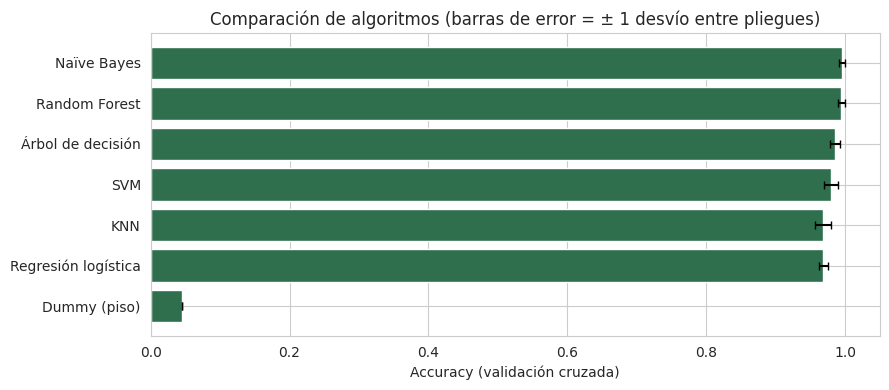

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos = {
    "Dummy (piso)":        DummyClassifier(strategy="most_frequent"),
    "Naïve Bayes":         GaussianNB(),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Árbol de decisión":   DecisionTreeClassifier(random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "SVM":                 make_pipeline(StandardScaler(), SVC()),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
}

filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    filas.append({"Algoritmo": nombre, "Accuracy CV": r["test_accuracy"].mean(),
                  "± desvío": r["test_accuracy"].std(), "F1 macro CV": r["test_f1_macro"].mean()})
tabla_cv = pd.DataFrame(filas).set_index("Algoritmo").sort_values("Accuracy CV", ascending=False)
display(tabla_cv)

fig, ax = plt.subplots(figsize=(9, 4))
t = tabla_cv.iloc[::-1]
ax.barh(t.index, t["Accuracy CV"], xerr=t["± desvío"], color="#2f6f4e", capsize=3)
ax.set_xlim(0, 1.05); ax.set_xlabel("Accuracy (validación cruzada)")
ax.set_title("Comparación de algoritmos (barras de error = ± 1 desvío entre pliegues)")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li><b>El piso (Dummy) acierta ~4,5 %</b> = 1 de 22: lo que daría el azar. Todos los demás lo superan por muchísimo.</li>
<li>Los 6 algoritmos superan el 96 %. <b>Naïve Bayes y Random Forest quedan prácticamente empatados arriba</b>: la diferencia entre ellos es menor que el desvío entre pliegues, o sea, <i>ruido</i>.</li>
<li>Que el algoritmo más simple casi empate con el más complejo es una señal: el problema está <b>muy bien estructurado</b> (cada cultivo ocupa una zona clara del espacio suelo-clima).</li>
</ul></div>

#### 2.2 · Ajuste de hiperparámetros: cada algoritmo tiene una "perilla" que se calibra

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Los <b>hiperparámetros</b> son las perillas que el humano gira <i>antes</i> de entrenar (cuántas preguntas puede hacer el árbol, cuántos vecinos consulta KNN…). Se eligen con <b>validación cruzada sobre train</b>, nunca mirando el test. Estas curvas además <b>enseñan</b> cómo funciona cada algoritmo.</div>

**a) Árbol de decisión: ¿cuántas preguntas encadenadas hacen falta?**

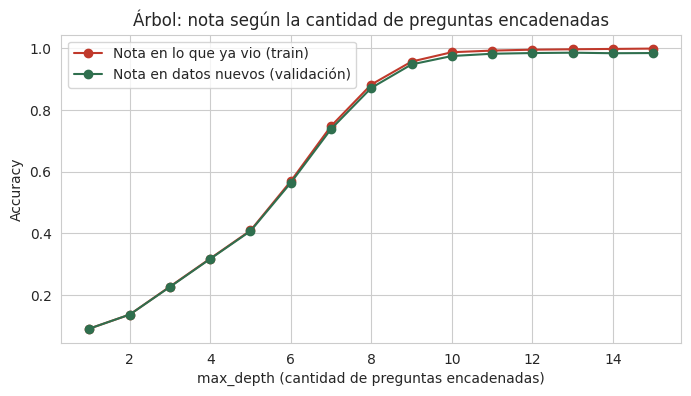

Mejor profundidad según validación: 13 (accuracy 0.986)


In [5]:
prof = range(1, 16)
res = [cross_validate(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_tr, y_tr, cv=cv,
                      return_train_score=True, n_jobs=-1) for d in prof]
tr_acc = [r["train_score"].mean() for r in res]; cv_acc = [r["test_score"].mean() for r in res]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(prof, tr_acc, "o-", label="Nota en lo que ya vio (train)", color="#c0392b")
ax.plot(prof, cv_acc, "o-", label="Nota en datos nuevos (validación)", color="#2f6f4e")
ax.set_xlabel("max_depth (cantidad de preguntas encadenadas)"); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title("Árbol: nota según la cantidad de preguntas encadenadas")
plt.show()
prof_ok = list(prof)[int(np.argmax(cv_acc))]
print(f"Mejor profundidad según validación: {prof_ok} (accuracy {max(cv_acc):.3f})")

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Con pocas preguntas el árbol es torpe: con 22 cultivos por distinguir, <b>necesita unas 10 preguntas encadenadas</b> para llegar al ~98 % (con 3 preguntas apenas separa 8 grupos). Después la curva se <b>aplana</b>: más profundidad ya no ayuda. Fijate que las dos curvas casi se superponen: acá <b>casi no hay sobreajuste</b> (la brecha es de ~1 punto) porque los cultivos están muy separados. <br><b>Ojo:</b> en datos reales y ruidosos esa brecha crece y es la señal clásica de <i>overfitting</i> (memorizar en vez de aprender); por eso conviene limitar la profundidad.</div>

**b) KNN: ¿a cuántos vecinos consulto?**

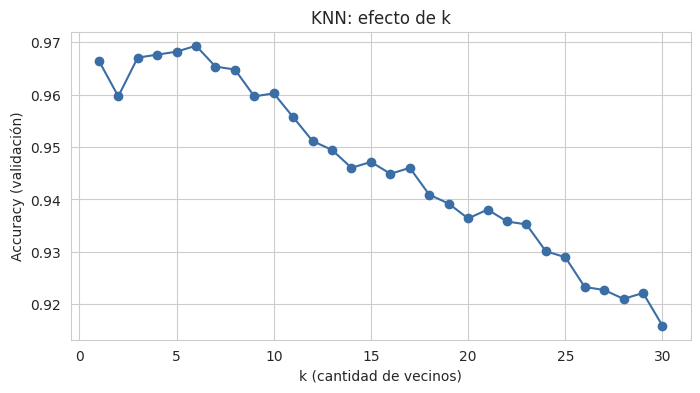

Mejor k: 6 (accuracy 0.969)


In [6]:
ks = range(1, 31)
knn_cv = [cross_validate(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), X_tr, y_tr, cv=cv,
                         n_jobs=-1)["test_score"].mean() for k in ks]
plt.figure(figsize=(8, 4)); plt.plot(ks, knn_cv, "o-", color="#3b6ea5")
plt.xlabel("k (cantidad de vecinos)"); plt.ylabel("Accuracy (validación)"); plt.title("KNN: efecto de k")
plt.show()
k_ok = list(ks)[int(np.argmax(knn_cv))]
print(f"Mejor k: {k_ok} (accuracy {max(knn_cv):.3f})")

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>En este dataset <b>los k chicos funcionan mejor</b> y la nota <b>cae al crecer k</b> (entre k=1 y k=6 la nota es ≈96,6–96,9 %: el mejor es k=6, pero por una diferencia mínima; con k=30 baja a ≈91,6 %). Tiene lógica: cada cultivo tiene solo ~80 parcelas de entrenamiento, así que con k grande el voto empieza a incluir parcelas de <i>otros</i> cultivos y la frontera se borra. <br><b>Ojo:</b> con k=1 el modelo es vulnerable a un vecino raro cuando las mediciones tienen ruido; un k intermedio (5 o 6) es más prudente. La diferencia entre k=1 y k=6 es ruido.</div>

**c) SVM y d) Random Forest: búsqueda en grilla (probar combinaciones de perillas)**

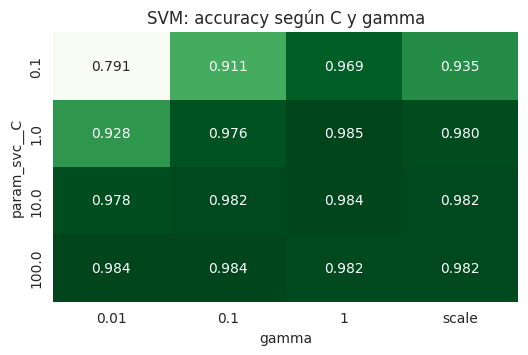

Mejores parámetros SVM: {'svc__C': 1, 'svc__gamma': 1} → 0.985


Mejores parámetros RF : {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100} → 0.994


,param_n_estimators,param_max_depth,param_max_features,mean_test_score
5,300,None,sqrt,0.994
4,100,None,sqrt,0.994
0,100,8,sqrt,0.993
1,300,8,sqrt,0.992
6,100,None,NaN,0.992


In [7]:
# --- SVM: C (qué tan estricto con los errores) y gamma (qué tan "local" es la frontera)
grilla_svm = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]}
gs_svm = GridSearchCV(make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
                      grilla_svm, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
mapa = pd.DataFrame(gs_svm.cv_results_)
mapa["gamma"] = mapa.param_svc__gamma.astype(str)
piv = mapa.pivot(index="param_svc__C", columns="gamma", values="mean_test_score")
plt.figure(figsize=(6, 3.5)); sns.heatmap(piv, annot=True, fmt=".3f", cmap="Greens", cbar=False)
plt.title("SVM: accuracy según C y gamma"); plt.show()
print("Mejores parámetros SVM:", gs_svm.best_params_, f"→ {gs_svm.best_score_:.3f}")

# --- Random Forest
grilla_rf = {"n_estimators": [100, 300], "max_depth": [8, None], "max_features": ["sqrt", None]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1), grilla_rf, cv=cv).fit(X_tr, y_tr)
print("Mejores parámetros RF :", gs_rf.best_params_, f"→ {gs_rf.best_score_:.3f}")
display(pd.DataFrame(gs_rf.cv_results_)[["param_n_estimators", "param_max_depth", "param_max_features",
                                         "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(5))

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>En el SVM, con <b>C chico y gamma chico</b> el modelo es demasiado rígido (la nota baja a ~79 %); pasado cierto punto <b>casi todas las combinaciones rinden parecido (~98 %)</b>: el problema es fácil y el ajuste fino aporta poco. En Random Forest, pasar de 100 a 300 árboles <b>no mejora</b> la nota: más no siempre es mejor.</div>

#### 2.3 · Modelos finales ajustados: el examen en el set de prueba (una sola vez)

In [8]:
finales = {
    "Naïve Bayes":         GaussianNB(),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_ok)),
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=prof_ok, random_state=SEED),
    "Random Forest":       gs_rf.best_estimator_,
    "SVM":                 gs_svm.best_estimator_,
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
}
filas = []
for nombre, m in finales.items():
    cv_s = cross_validate(m, X_tr, y_tr, cv=cv, scoring="accuracy", n_jobs=-1)["test_score"].mean()
    m.fit(X_tr, y_tr); p = m.predict(X_te)
    filas.append({"Algoritmo": nombre, "Accuracy CV (train)": cv_s,
                  "Accuracy TEST": accuracy_score(y_te, p), "F1 macro TEST": f1_score(y_te, p, average="macro"),
                  "Errores (de 440)": int((p != y_te).sum())})
tabla_test = pd.DataFrame(filas).set_index("Algoritmo").sort_values("Accuracy TEST", ascending=False)
tabla_test["Errores (de 440)"] = tabla_test["Errores (de 440)"].astype(int)
tabla_test

,Accuracy CV (train),Accuracy TEST,F1 macro TEST,Errores (de 440)
Algoritmo,,,,
Naïve Bayes,0.995,0.995,0.995,2
Random Forest,0.994,0.995,0.995,2
SVM,0.985,0.991,0.991,4
Árbol de decisión,0.986,0.982,0.982,8
KNN,0.969,0.980,0.979,9
Regresión logística,0.968,0.973,0.972,12


<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br><b>No sobreinterpretar diferencias chicas.</b> Con 440 filas de test, un punto de accuracy son unos 4 errores. Si dos modelos difieren en 1 o 2 errores, <b>están empatados</b> para cualquier fin práctico.
<br><br>La elección del modelo final se hizo por <b>validación cruzada (train)</b>, no por el test: el test solo <i>confirma</i> que lo aprendido generaliza.</div>

#### 2.4 · ¿Dónde se equivoca el mejor modelo? Matriz de confusión

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>La <b>matriz de confusión</b> es una tabla de doble entrada: en las filas está el cultivo <i>real</i>, en las columnas lo que <i>predijo</i> el modelo. Lo ideal es una diagonal perfecta; todo lo que cae fuera son confusiones.</div>

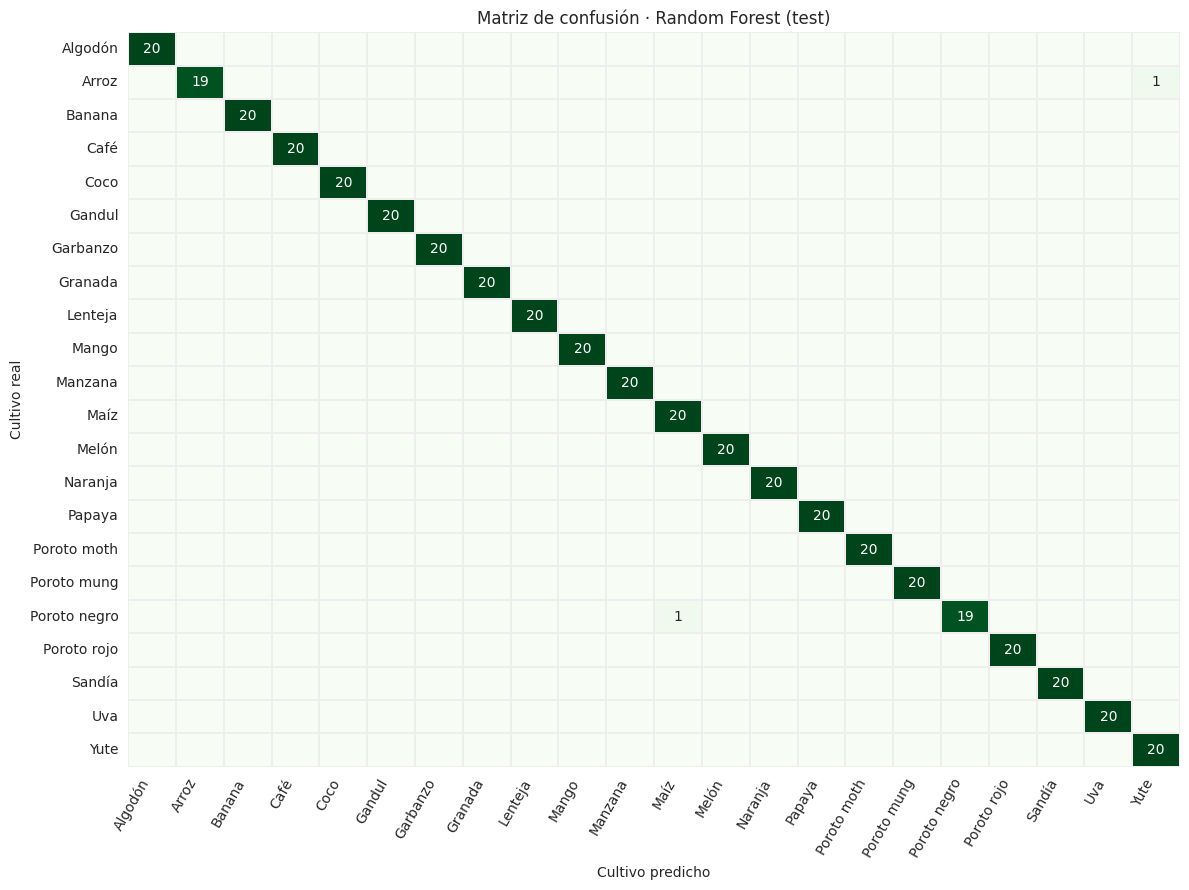

Confusiones del modelo:


,real,predicho,casos
0,Poroto negro,Maíz,1
1,Arroz,Yute,1


              precision    recall  f1-score   support

     Algodón      1.000     1.000     1.000        20
       Arroz      1.000     0.950     0.974        20
      Banana      1.000     1.000     1.000        20
        Café      1.000     1.000     1.000        20
        Coco      1.000     1.000     1.000        20
      Gandul      1.000     1.000     1.000        20
    Garbanzo      1.000     1.000     1.000        20
     Granada      1.000     1.000     1.000        20
     Lenteja      1.000     1.000     1.000        20
       Mango      1.000     1.000     1.000        20
     Manzana      1.000     1.000     1.000        20
        Maíz      0.952     1.000     0.976        20
       Melón      1.000     1.000     1.000        20
     Naranja      1.000     1.000     1.000        20
      Papaya      1.000     1.000     1.000        20
 Poroto moth      1.000     1.000     1.000        20
 Poroto mung      1.000     1.000     1.000        20
Poroto negro      1.000    

In [9]:
modelo_final = finales["Random Forest"]
pred = modelo_final.predict(X_te)
clases = sorted(y_tr.unique())
cm = confusion_matrix(y_te, pred, labels=clases)

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(cm, annot=np.where(cm > 0, cm, ""), fmt="", cmap="Greens", cbar=False,
            xticklabels=clases, yticklabels=clases, ax=ax, linewidths=.3, linecolor="#eee")
ax.set_xlabel("Cultivo predicho"); ax.set_ylabel("Cultivo real"); ax.set_title("Matriz de confusión · Random Forest (test)")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

errores = pd.DataFrame({"real": y_te.values, "predicho": pred})
errores = errores[errores.real != errores.predicho].value_counts().reset_index(name="casos")
print("Confusiones del modelo:"); display(errores)
print(classification_report(y_te, pred, digits=3))

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Casi todo está en la diagonal: <b>solo 2 errores en 440 parcelas</b> (un <i>poroto negro</i> (<i>blackgram</i> en el original) predicho como maíz y un arroz predicho como yute). Con tan pocos errores no se puede sacar una conclusión agronómica firme; pero la confusión <b>arroz ↔ yute</b> tiene sentido: ambos son cultivos de clima cálido y húmedo, y más adelante (Parte 6) el dendrograma los pone en la misma familia.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 3</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">¿Alguna variable se lleva todo el peso?</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Importancia, permutación y ablación: que una variable fuerte no tape al resto del contexto</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Pregunta clave: <b>¿el modelo "decide" mirando una sola variable (por ejemplo la lluvia) e ignora todo lo demás?</b> Eso sería un problema porque (1) el modelo sería frágil si esa medición falla y (2) estaríamos desperdiciando el resto de la información.
<br><br>Lo comprobamos con <b>4 pruebas distintas</b> (si todas coinciden, la conclusión es sólida).</div>

#### 3.1 · Prueba 1: importancia interna del Random Forest

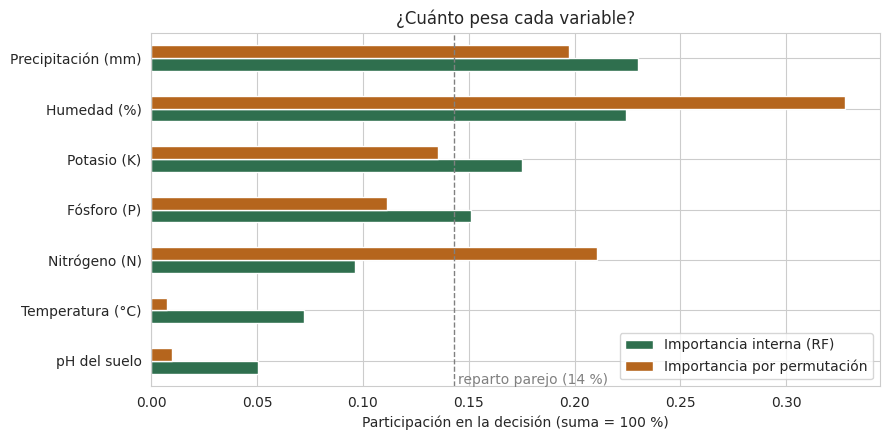

Variable más pesada: Precipitación (mm) (23.0%) | menos pesada: pH del suelo (5.1%)


In [10]:
rf = finales["Random Forest"]
imp_interna = pd.Series(rf.feature_importances_, index=VARS)

from sklearn.inspection import permutation_importance
pi = permutation_importance(rf, X_te, y_te, n_repeats=15, random_state=SEED, n_jobs=-1)
imp_perm = pd.Series(pi.importances_mean, index=VARS)

comp = pd.DataFrame({"Importancia interna (RF)": imp_interna / imp_interna.sum(),
                     "Importancia por permutación": imp_perm.clip(lower=0) / imp_perm.clip(lower=0).sum()}
                    ).sort_values("Importancia interna (RF)")
comp.plot.barh(figsize=(9, 4.5), color=["#2f6f4e", "#b5651d"])
plt.xlabel("Participación en la decisión (suma = 100 %)"); plt.title("¿Cuánto pesa cada variable?")
plt.axvline(1/7, color="gray", ls="--", lw=1); plt.text(1/7 + .002, -.45, "reparto parejo (14 %)", color="gray")
plt.tight_layout(); plt.show()
print(f"Variable más pesada: {imp_interna.idxmax()} ({imp_interna.max()/imp_interna.sum():.1%}) | "
      f"menos pesada: {imp_interna.idxmin()} ({imp_interna.min()/imp_interna.sum():.1%})")

<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Importancia interna</b>: cuánto usó cada variable el bosque para dividir los datos (puede favorecer variables continuas). <b>Importancia por permutación</b>: se "desordena" una columna en el test y se mide cuánto cae la nota; si no cae, la variable no hacía falta <i>para ese modelo</i>. Dos métodos distintos que se contrastan entre sí.</div>

#### 3.2 · Pruebas 2 y 3: cada variable sola vs. el modelo sin esa variable

Accuracy con las 7 variables: 0.994  |  azar: 0.045


,Sola (solo esta),Sin ella (las otras 6),Caída al sacarla
Variable,,,
Precipitación (mm),0.307,0.965,0.029
Humedad (%),0.316,0.981,0.013
Fósforo (P),0.219,0.989,0.005
Potasio (K),0.314,0.989,0.005
Nitrógeno (N),0.146,0.993,0.001
Temperatura (°C),0.174,0.993,0.001
pH del suelo,0.138,0.994,-0.001


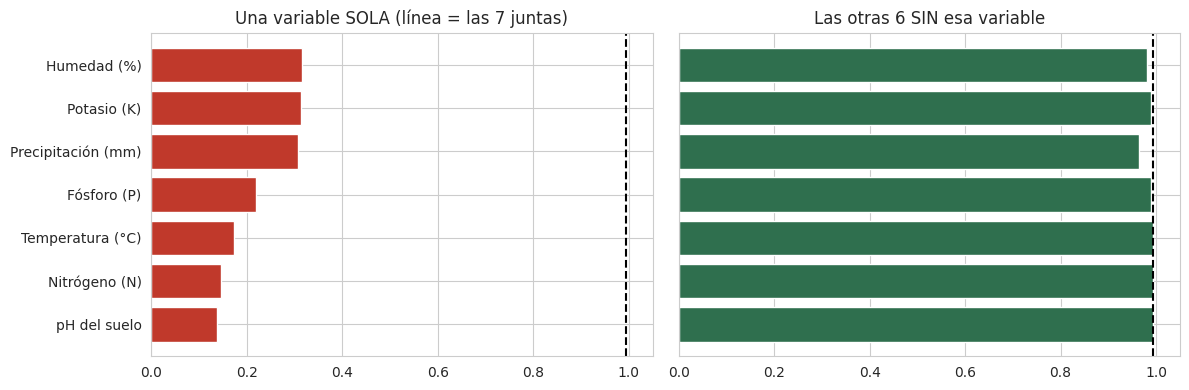

In [11]:
rf_rapido = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1)
def nota(cols):
    return cross_validate(rf_rapido, X_tr[cols], y_tr, cv=cv, n_jobs=-1)["test_score"].mean()

base = nota(VARS)
filas = []
for v in VARS:
    filas.append({"Variable": v, "Sola (solo esta)": nota([v]),
                  "Sin ella (las otras 6)": nota([c for c in VARS if c != v])})
abl = pd.DataFrame(filas).set_index("Variable")
abl["Caída al sacarla"] = base - abl["Sin ella (las otras 6)"]
print(f"Accuracy con las 7 variables: {base:.3f}  |  azar: {1/22:.3f}")
display(abl.sort_values("Caída al sacarla", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
orden = abl.sort_values("Sola (solo esta)").index
ax[0].barh(orden, abl.loc[orden, "Sola (solo esta)"], color="#c0392b"); ax[0].axvline(base, color="k", ls="--")
ax[0].set_title("Una variable SOLA (línea = las 7 juntas)"); ax[0].set_xlim(0, 1.05)
ax[1].barh(orden, abl.loc[orden, "Sin ella (las otras 6)"], color="#2f6f4e"); ax[1].axvline(base, color="k", ls="--")
ax[1].set_title("Las otras 6 SIN esa variable"); ax[1].set_xlim(0, 1.05)
plt.tight_layout(); plt.show()

#### 3.3 · Prueba 4: grupos de variables (suelo vs. clima) y quitar las más fuertes

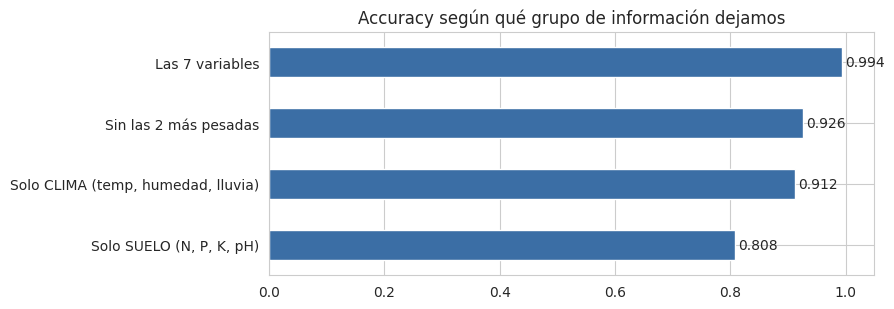

Las 2 más pesadas que se sacaron: ['Precipitación (mm)', 'Humedad (%)']


In [12]:
grupos = {
    "Las 7 variables": VARS,
    "Solo SUELO (N, P, K, pH)": SUELO,
    "Solo CLIMA (temp, humedad, lluvia)": CLIMA,
    "Sin las 2 más pesadas": [v for v in VARS if v not in list(imp_interna.sort_values(ascending=False).index[:2])],
}
res_g = pd.Series({k: nota(v) for k, v in grupos.items()}).sort_values()
res_g.plot.barh(figsize=(9, 3.2), color="#3b6ea5"); plt.xlim(0, 1.05)
for i, v in enumerate(res_g): plt.text(v + .005, i, f"{v:.3f}", va="center")
plt.title("Accuracy según qué grupo de información dejamos"); plt.tight_layout(); plt.show()
print("Las 2 más pesadas que se sacaron:", list(imp_interna.sort_values(ascending=False).index[:2]))

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li><b>Ninguna variable alcanza sola</b>: la mejor llega a ~31 %, lejos del ~99 % del conjunto. Los cultivos <i>se parecen</i> cuando se miran de a una dimensión (muchos comparten rangos de lluvia o de potasio).</li>
<li><b>Sacar cualquier variable casi no cambia nada</b> (la caída máxima es de apenas unos puntos): la información está <b>repartida y es redundante</b>; el modelo se las arregla con el resto.</li>
<li><b>Solo suelo: ~81 %</b> · <b>solo clima: ~91 %</b> · <b>juntos: ~99 %</b>. Se complementan: ningún grupo alcanza por sí solo. Y aun <b>sin las dos variables más pesadas</b> (lluvia y humedad) el modelo se mantiene en ~93 %.</li>
<li><b>Conclusión:</b> el conocimiento está en la <b>combinación</b> de variables, no en una "estrella". Ninguna variable deja al resto de contexto atrás; la precipitación (≈23 % de la decisión) y la humedad pesan algo más, pero el modelo no depende de ellas.</li>
</ul></div>

<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br>Esta robustez es una <b>buena noticia para el modelo</b> pero también una pista sobre el dataset: es muy limpio y los cultivos están muy bien separados (100 casos exactos por clase). En el campo real, con mediciones ruidosas y cultivos que se superponen, esperaríamos un desempeño menor.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 4</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Del modelo a la recomendación útil</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Top-3 de cultivos con probabilidad y rendimiento real (Dataset B)</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>A un productor no le sirve un único nombre: le sirve <b>«te recomiendo A, pero B y C también son viables»</b>. El Random Forest puede dar <b>probabilidades</b> y, con el rendimiento real del Dataset B (<code>cultivos_enriquecido.csv</code>), ordenamos las alternativas por lo que realmente rinde cada cultivo.</div>

In [13]:
enr = pd.read_csv(RUTAS["enriquecido"], encoding="utf-8-sig")
if "cultivo_etapa1" in enr.columns:              # versión original (nombres en inglés)
    enr = enr.set_index("cultivo_etapa1"); enr.index = enr.index.map(CULT_A)        # mismos nombres en castellano
else:                                            # versión ya en castellano
    enr = enr.set_index("cultivo").rename(columns={"rendimiento_mediano_t_ha": "rendimiento_mediano"})

# ¿Con qué frecuencia el cultivo correcto está entre las 3 primeras opciones?
proba = rf.predict_proba(X_te); clases_rf = rf.classes_
top3 = clases_rf[np.argsort(-proba, axis=1)[:, :3]]
acierta_top3 = np.mean([y_te.iloc[i] in top3[i] for i in range(len(y_te))])
acierta_top1 = np.mean(top3[:, 0] == y_te.values)
print(f"Acierta en el 1.º: {acierta_top1:.1%}  |  Está dentro del Top-3: {acierta_top3:.1%}")

def recomendar(parcela):
    p = pd.DataFrame([parcela])[VARS]
    pr = pd.Series(rf.predict_proba(p)[0], index=clases_rf).sort_values(ascending=False).head(3)
    out = pd.DataFrame({"Probabilidad": pr})
    out["Rend. mediano real (t/ha)"] = [enr.rendimiento_mediano.get(c, np.nan) for c in out.index]
    return out

ejemplo = dict(zip(VARS, [90, 42, 43, 21.0, 82.0, 6.5, 200.0]))
print("\nParcela de ejemplo:", ejemplo)
recomendar(ejemplo)

Acierta en el 1.º: 99.5%  |  Está dentro del Top-3: 100.0%

Parcela de ejemplo: {'Nitrógeno (N)': 90, 'Fósforo (P)': 42, 'Potasio (K)': 43, 'Temperatura (°C)': 21.0, 'Humedad (%)': 82.0, 'pH del suelo': 6.5, 'Precipitación (mm)': 200.0}


,Probabilidad,Rend. mediano real (t/ha)
Arroz,0.880,1.930
Yute,0.120,9.330
Banana,0.000,22.000


<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br><b>Cuidado al ordenar por rendimiento.</b> Un cultivo con más toneladas por hectárea <i>no es</i> necesariamente el más conveniente: falta el <b>precio</b> (1 t de banana no vale lo que 1 t de garbanzo) y algunos cultivos (por ejemplo yute y algodón) se informan en el dato oficial en unidades distintas de toneladas, por lo que su "t/ha" no es comparable (verificar en la fuente). En el ejemplo, el yute figura con ~9 t/ha frente a ~1,9 del arroz: es un artefacto de unidades, no una ventaja real. Este orden es solo un <b>dato de apoyo</b>, no la decisión.</div>

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>La recomendación viene con <b>nivel de confianza</b>. Cuando la probabilidad del 1.º es muy alta, la decisión es clara; cuando hay dos cultivos con probabilidades parecidas, el productor puede elegir el de mayor rendimiento o mejor precio. <i>(Algunos cultivos no tienen rendimiento en el Dataset B porque no figuran allí.)</i></div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 5</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Aprendizaje supervisado · ¿cuánto rinde un cultivo?</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Regresión sobre el dato real y sucio (Dataset B) — y la lección de la variable dominante</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Hasta acá <b>clasificamos</b> (¿qué cultivo?). Ahora <b>predecimos un número</b> (¿cuántas toneladas por hectárea?): eso es <b>regresión</b>. Usamos el dato oficial de India, que <b>no es perfecto</b>: es el archivo real que limpiamos en la Etapa 1-B (y que en el Taller 2b repetimos de forma simple).</div>

#### 5.1 · Qué datos usamos y por qué filtramos algunos

> ℹ️ **Nota técnica sobre los datos atípicos:** los CSV limpios entregados no incluyen la columna `yield_outlier` de la Etapa 1-B, así que se recalcula acá con la misma regla: el rendimiento queda fuera de **Q1 − 3·IQR / Q3 + 3·IQR dentro de cada cultivo** (cuartiles sobre filas válidas). Da exactamente las mismas 231.248 filas confiables de la Etapa 1-B. El conteo total de atípicos que se imprime puede diferir del de corridas viejas, pero no cambia nada del modelado.

In [14]:
d = pd.read_csv(RUTAS["limpio_B"], encoding="utf-8-sig")
print("Filas del dataset limpio:", len(d))
d = d.rename(columns=COLUMNAS_B_FLAGS)
d["Cultivo"] = d.Cultivo.replace(CULT_B); d["Temporada"] = d.Temporada.replace(TEMPORADA); d["Estado"] = d.Estado.replace(ESTADO)
assert d.Cultivo.isin(CULT_B.values()).all() and d.Temporada.isin(TEMPORADA.values()).all(), "Hay valores sin traducir en el Dataset B"

# La columna de "rendimiento atípico" de la Etapa 1-B no viene en los CSV entregados: se recalcula acá (regla explícita y reproducible)
def marcar_atipicos(d, k=3.0):
    """Rendimiento atípico: fuera de [Q1 - k·IQR, Q3 + k·IQR] dentro de cada cultivo (k=3 → valores 'muy lejanos').
    Los cuartiles se calculan solo sobre filas válidas (unidad comparable, producción medida y > 0).
    Esta regla reproduce exactamente la Etapa 1-B: 231.248 filas confiables."""
    val = d.unidad_comparable & ~d.produccion_imputada & ~d.produccion_nula_reportada & (d.Rendimiento > 0) & (d.Area_ha > 0)
    g = d.Rendimiento.where(val).groupby(d.Cultivo)
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    return ((d.Rendimiento > q3 + k * (q3 - q1)) | (d.Rendimiento < q1 - k * (q3 - q1))).fillna(False)
if "rendimiento_atipico" not in d.columns:
    d["rendimiento_atipico"] = marcar_atipicos(d)

# Hallazgo del Taller 2b: al unificar 'Paddy' y 'Rice' quedaron filas idénticas (arroz de Assam cargado dos veces)
COLS_ID = ["Estado", "Distrito", "Anio", "Temporada", "Cultivo", "Area_ha", "Produccion_ton"]
n_dup = d.duplicated(COLS_ID).sum()
d = d.drop_duplicates(COLS_ID).reset_index(drop=True)
print(f"Se eliminaron {n_dup} filas duplicadas exactas → quedan {len(d):,} filas")

# Usamos solo registros "confiables" (las banderas de trazabilidad de la Etapa 1-B):
ok = d[d.unidad_comparable & ~d.produccion_imputada & ~d.produccion_nula_reportada
       & ~d.rendimiento_atipico & d.Rendimiento.notna() & (d.Area_ha > 0)].copy()
print(f"Filas confiables para modelar: {len(ok):,} ({len(ok)/len(d):.1%})")

ok["logRend"] = np.log(ok.Rendimiento)      # trabajamos en logaritmo: el rendimiento es muy asimétrico
ok["logArea"] = np.log(ok.Area_ha)
print("\nQué se descartó:",
      f"\n  unidades no comparables (coco, areca, cajú): {(~d.unidad_comparable).sum():,}",
      f"\n  producción imputada (estimada, no medida):  {d.produccion_imputada.sum():,}",
      f"\n  producción = 0 reportada:                    {d.produccion_nula_reportada.sum():,}",
      f"\n  rendimientos atípicos:                       {d.rendimiento_atipico.sum():,}")
ok[["Estado", "Cultivo", "Temporada", "Anio", "Area_ha", "Rendimiento"]].head()

Filas del dataset limpio: 244844


Se eliminaron 0 filas duplicadas exactas → quedan 244,844 filas
Filas confiables para modelar: 231,248 (94.4%)

Qué se descartó: 
  unidades no comparables (coco, areca, cajú): 4,725 
  producción imputada (estimada, no medida):  3,688 
  producción = 0 reportada:                    3,510 
  rendimientos atípicos:                       2,079


,Estado,Cultivo,Temporada,Anio,Area_ha,Rendimiento
1,Islas Andamán y Nicobar,Otras legumbres Kharif,Kharif (monzón),2000,2.000,0.500
2,Islas Andamán y Nicobar,Arroz,Kharif (monzón),2000,102.000,3.147
3,Islas Andamán y Nicobar,Banana,Todo el año,2000,176.000,3.642
6,Islas Andamán y Nicobar,Jengibre seco,Todo el año,2000,36.000,2.778
7,Islas Andamán y Nicobar,Caña de azúcar,Todo el año,2000,1.000,2.000


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Por qué logaritmo:</b> el rendimiento de la caña (~70 t/ha) y el del poroto (~0,5 t/ha) difieren 100 veces. Con el logaritmo, un error del 20 % pesa igual en ambos. <b>Por qué descartamos filas:</b> una producción <i>imputada</i> (estimada) usada como respuesta haría que el modelo aprenda de su propia estimación. Las banderas que armamos en la Etapa 1-B sirven justamente para esto.</div>

#### 5.2 · Cuatro modelos, con división **temporal** (entrenamos con el pasado, predecimos el futuro)

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error

CATS = ["Estado", "Cultivo", "Temporada"]; NUMS = ["Anio", "logArea"]
pasado = ok[ok.Anio <= 2010]; futuro = ok[ok.Anio > 2010]
print(f"Entrenamiento: {len(pasado):,} filas (1997–2010) | Prueba: {len(futuro):,} filas (2011–2015)")

def pre_onehot(poly=False):
    num = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False)) if poly else StandardScaler()
    return ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATS), ("n", num, NUMS)])
pre_ord = ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATS),
                             ("n", "passthrough", NUMS)])

reg = {
    "Piso (siempre la mediana)":    make_pipeline(pre_onehot(), DummyRegressor(strategy="median")),
    "Regresión lineal":             make_pipeline(pre_onehot(), LinearRegression()),
    "Regresión polinomial (gr. 2)": make_pipeline(pre_onehot(poly=True), LinearRegression()),
    "Random Forest":                make_pipeline(pre_ord, RandomForestRegressor(100, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    "Gradient Boosting":            make_pipeline(pre_ord, HistGradientBoostingRegressor(random_state=SEED)),
}
filas = []
for nom, m in reg.items():
    m.fit(pasado[CATS + NUMS], pasado.logRend); p = m.predict(futuro[CATS + NUMS])
    err_pct = (np.abs(np.exp(p) - futuro.Rendimiento) / futuro.Rendimiento).median() * 100
    filas.append({"Modelo": nom, "R²": r2_score(futuro.logRend, p),
                  "Error medio (log)": mean_absolute_error(futuro.logRend, p), "Error mediano %": err_pct})
tabla_reg = pd.DataFrame(filas).set_index("Modelo")
tabla_reg

Entrenamiento: 181,508 filas (1997–2010) | Prueba: 49,740 filas (2011–2015)


,R²,Error medio (log),Error mediano %
Modelo,,,
Piso (siempre la mediana),-0.081,1.019,65.048
Regresión lineal,0.821,0.425,31.739
Regresión polinomial (gr. 2),0.822,0.422,31.529
Random Forest,0.843,0.336,20.564
Gradient Boosting,0.800,0.417,29.505


<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>R²</b> indica qué parte de la variación del rendimiento explica el modelo (0 = nada, 1 = todo). La <b>división temporal</b> es más exigente que una al azar: simula lo que de verdad queremos hacer, predecir campañas que todavía no ocurrieron.</div>

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Todos explican entre 80 % y 84 % de la variación (el piso, en cambio, da R² ≈ 0). El polinomial <b>no mejora</b> a la lineal (las variables numéricas casi no tienen curvatura que capturar). El <b>Random Forest</b> es el mejor (R² ≈ 0,84 y error mediano ≈ 21 % contra ≈ 32 % de la lineal); Gradient Boosting no aporta mejora. <b>Pero ojo: ese 80 % es engañoso</b>. Veamos por qué.</div>

<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br><b>Una cifra que se movió, y por qué.</b> Antes de traducir los nombres, el Random Forest daba R² ≈ 0,82; al traducir dio ≈ 0,84. Los modelos de árboles reciben las categorías numeradas (0, 1, 2…) y ese orden, que es alfabético, es arbitrario: al cambiar los nombres cambió el orden y los árboles se partieron distinto. La regresión lineal, que usa una codificación sin orden (<i>one-hot</i>), no tiene este problema. Por eso conviene informar el Random Forest como <b>«entre 0,82 y 0,84»</b> y no como una cifra exacta.</div>

#### 5.3 · La lección de la variable dominante

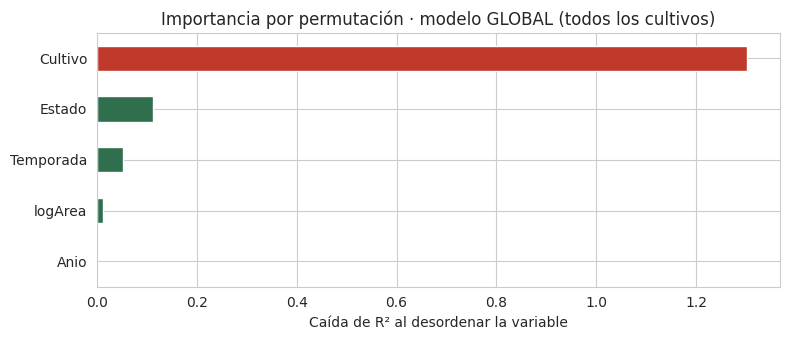

Cultivo     0.881
Estado      0.076
Temporada   0.035
logArea     0.007
Anio        0.000


In [16]:
gb = reg["Gradient Boosting"]
pi = permutation_importance(gb, futuro[CATS + NUMS], futuro.logRend, n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=CATS + NUMS).sort_values()
imp.plot.barh(figsize=(8, 3.5), color=["#2f6f4e"] * 4 + ["#c0392b"])
plt.xlabel("Caída de R² al desordenar la variable"); plt.title("Importancia por permutación · modelo GLOBAL (todos los cultivos)")
plt.tight_layout(); plt.show()
print((imp / imp.sum()).round(3).sort_values(ascending=False).to_string())

<div style="border-left:6px solid #b5651d;background:#fffaf2;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>⚠️ Ojo</b><br><b><code>Cultivo</code> se lleva casi todo el peso.</b> Es lógico: la caña rinde 70 t/ha y el poroto 0,5. El modelo "aprendió" sobre todo <b>qué cultivo es</b>. Ese 80 % de R² se debe en gran parte a eso, y deja en la sombra el resto del contexto (estado, temporada, superficie).
<br><br>Si lo que le interesa a un agrónomo es <i>"¿por qué mi maíz rinde menos que el del vecino?"</i>, hay que <b>sacar esa variable dominante del medio</b>: modelar <b>dentro de un mismo cultivo</b>.</div>

#### 5.4 · Quitando la variable dominante: un modelo por cultivo

,Filas,R² lineal,R² Grad. Boosting
Cultivo,,,
Arroz,15250,0.154,0.142
Trigo,7874,0.564,0.591
Maíz,13566,0.289,0.357
Caña de azúcar,7759,0.693,0.729


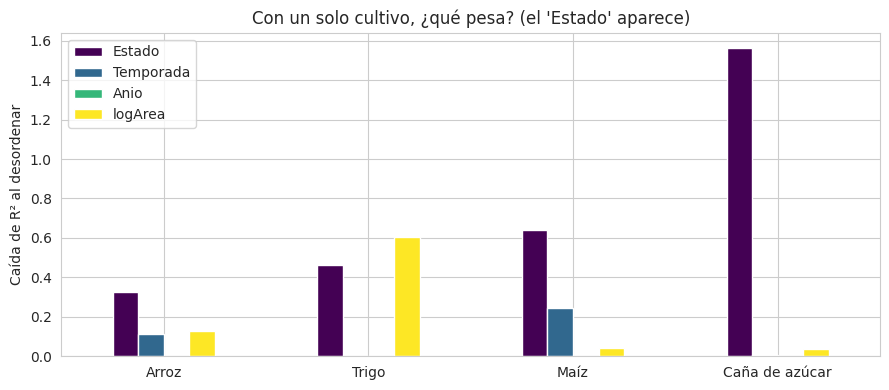

In [17]:
filas, imps = [], {}
for cultivo in ["Arroz", "Trigo", "Maíz", "Caña de azúcar"]:
    s = ok[ok.Cultivo == cultivo]; a, b = s[s.Anio <= 2010], s[s.Anio > 2010]
    f = ["Estado", "Temporada"] + NUMS
    pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Estado", "Temporada"]),
                             ("n", StandardScaler(), NUMS)])
    r2s = {}
    for nom, m in [("Lineal", LinearRegression()), ("Gradient Boosting", HistGradientBoostingRegressor(random_state=SEED))]:
        p = make_pipeline(pre, m).fit(a[f], a.logRend); r2s[nom] = r2_score(b.logRend, p.predict(b[f]))
    pi = permutation_importance(p, b[f], b.logRend, n_repeats=3, random_state=SEED)
    imps[cultivo] = pd.Series(pi.importances_mean, index=f)
    filas.append({"Cultivo": cultivo, "Filas": len(s), "R² lineal": r2s["Lineal"], "R² Grad. Boosting": r2s["Gradient Boosting"]})
display(pd.DataFrame(filas).set_index("Cultivo"))

pd.DataFrame(imps).T.plot.bar(figsize=(9, 4), rot=0, colormap="viridis")
plt.ylabel("Caída de R² al desordenar"); plt.title("Con un solo cultivo, ¿qué pesa? (el 'Estado' aparece)")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li>Sin la variable dominante, <b>el R² cambia mucho según el cultivo</b>: ≈0,15 en arroz, ≈0,3 en maíz, ≈0,6 en trigo y ≈0,7 en caña de azúcar. <i>Dentro de un cultivo</i> predecir el rendimiento es bastante más difícil que lo que el 80 % global sugería, sobre todo en arroz.</li>
<li>Aparece el contexto que antes quedaba tapado: el <b>Estado</b> (suelo, clima y manejo de la zona) es el factor que más pesa en arroz, maíz y caña; en el trigo pesa más la <b>superficie</b>; la <b>temporada</b> importa sobre todo en arroz y maíz.</li>
<li>El <code>Anio</code> da importancia casi nula en los árboles porque <b>los árboles no pueden extrapolar</b>: no saben qué hacer con años (2011–2015) que no vieron al entrenar. La regresión lineal sí puede capturar una tendencia (próxima celda).</li>
<li>El R² moderado es honesto: <b>faltan las variables que realmente explican el rendimiento</b> (lluvia de la campaña, riego, fertilización, variedad). Ese es el puente natural con el Dataset A.</li>
</ul></div>

In [18]:
# Tendencia anual con regresión lineal (a diferencia de los árboles, sí extrapola)
filas = []
for cultivo in ["Arroz", "Trigo", "Maíz", "Caña de azúcar"]:
    s = ok[ok.Cultivo == cultivo]
    X_ = pd.get_dummies(s[["Estado", "Temporada"]], drop_first=True).astype(float)
    X_["Anio"] = s.Anio - s.Anio.mean(); X_["logArea"] = s.logArea
    lm = LinearRegression().fit(X_, s.logRend)
    filas.append({"Cultivo": cultivo, "Cambio anual del rendimiento": np.exp(lm.coef_[list(X_.columns).index("Anio")]) - 1})
pd.DataFrame(filas).set_index("Cultivo").style.format("{:+.2%}")

,Cambio anual del rendimiento
Cultivo,
Arroz,+1.65%
Trigo,+1.60%
Maíz,+2.58%
Caña de azúcar,+0.76%


<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>La regresión lineal permite una frase para cualquier persona: <i>«manteniendo el estado, la temporada y la superficie constantes, el rendimiento cambia X % por año»</i>. En nuestros datos: <b>arroz ≈ +1,7 %</b>, <b>trigo ≈ +1,6 %</b>, <b>maíz ≈ +2,6 %</b> y <b>caña ≈ +0,8 % anual</b>. Es la ventaja de los modelos simples: <b>se pueden leer</b>.</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 6</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Aprendizaje no supervisado · ¿qué estructura esconden los datos?</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Sin mirar la etiqueta: PCA, K-Means, clustering jerárquico y mezcla gaussiana</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Aprendizaje no supervisado = <b>explorar sin respuestas a la vista</b>. Le damos al algoritmo las 2.200 parcelas <b>sin decirle qué cultivo es cada una</b> y le pedimos que encuentre grupos por su cuenta. Después comparamos: ¿los grupos que encontró coinciden con los cultivos reales?
<br><br>Es como entrar a una góndola sin carteles y agrupar productos por parecido: si lo hacés bien, terminás reconstruyendo las secciones del supermercado.</div>

In [19]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import homogeneity_score, completeness_score

full = pd.concat([tr, te], ignore_index=True)           # las 2.200 parcelas (no se usa la etiqueta para entrenar)
Xs = StandardScaler().fit_transform(full[VARS])         # escalar es OBLIGATORIO en algoritmos de distancia
y_real = full["Cultivo"].values
print("Matriz:", Xs.shape, "→ las etiquetas solo se usarán DESPUÉS, para comparar.")

Matriz: (2200, 7) → las etiquetas solo se usarán DESPUÉS, para comparar.


### 6.1 · PCA — la "foto" en 2D de un objeto de 7 dimensiones

<div style="border-left:6px solid #444;background:#f7f7f7;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🧩 Ficha del algoritmo</b><br><b>Idea:</b> con 7 variables no podemos <i>ver</i> los datos. PCA busca los ejes (componentes) que capturan la mayor variación posible, como elegir el mejor ángulo para fotografiar una escultura.<br><b>Parámetro:</b> cuántos componentes quedarse.<br><b>Qué muestra:</b> cuánta información se pierde al resumir y qué variables viajan juntas.</div>

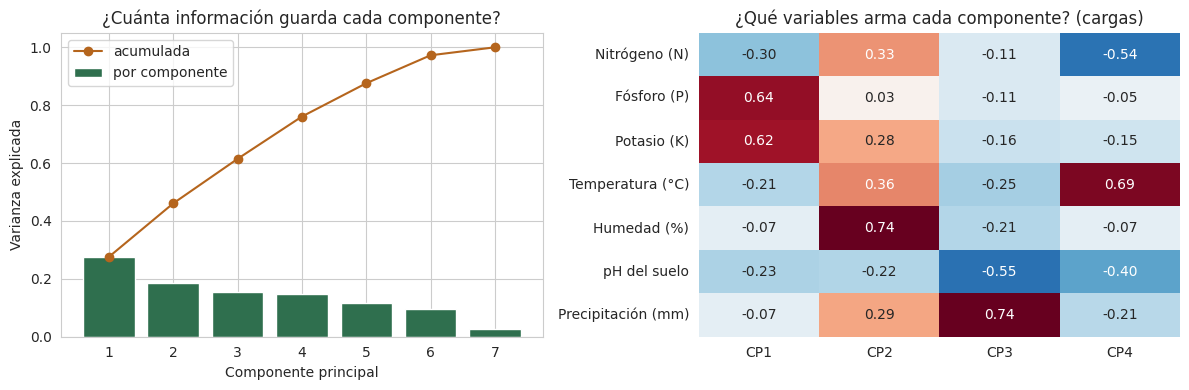

Varianza acumulada con 2 comp.: 46.1% | con 3: 61.5% | con 5: 87.6%


In [20]:
pca = PCA().fit(Xs)
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 8), ev, color="#2f6f4e", label="por componente")
ax[0].plot(range(1, 8), np.cumsum(ev), "o-", color="#b5651d", label="acumulada")
ax[0].set_xlabel("Componente principal"); ax[0].set_ylabel("Varianza explicada"); ax[0].legend()
ax[0].set_title("¿Cuánta información guarda cada componente?")
carga = pd.DataFrame(pca.components_[:4].T, index=VARS, columns=[f"CP{i}" for i in range(1, 5)])
sns.heatmap(carga, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False, ax=ax[1])
ax[1].set_title("¿Qué variables arma cada componente? (cargas)")
plt.tight_layout(); plt.show()
print("Varianza acumulada con 2 comp.:", f"{ev[:2].sum():.1%}", "| con 3:", f"{ev[:3].sum():.1%}", "| con 5:", f"{ev[:5].sum():.1%}")

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li>Los componentes <b>no se concentran</b> en uno o dos: 2 componentes retienen solo ~46 % de la información y hacen falta 5 de 7 para llegar a ~88 %. Eso confirma lo visto en la Parte 3: <b>la información está repartida</b> y las variables casi no son redundantes (no hay "multicolinealidad" que PCA tenga que resolver).</li>
<li>El heatmap muestra qué mezcla cada componente: el <b>CP1</b> es sobre todo <b>fósforo + potasio</b> (que además están correlacionados, r ≈ 0,74: la única pareja realmente redundante); el <b>CP2</b> es la <b>humedad</b>; el <b>CP3</b>, la <b>lluvia</b> (con el pH); y el <b>CP4</b>, la <b>temperatura</b> (con el nitrógeno).</li>
<li>Por eso en la Etapa 1 se decidió <b>no usar PCA para modelar</b> (se perdería interpretabilidad sin ganar nada) sino solo para <b>visualizar</b>, que es lo que hacemos ahora.</li>
</ul></div>

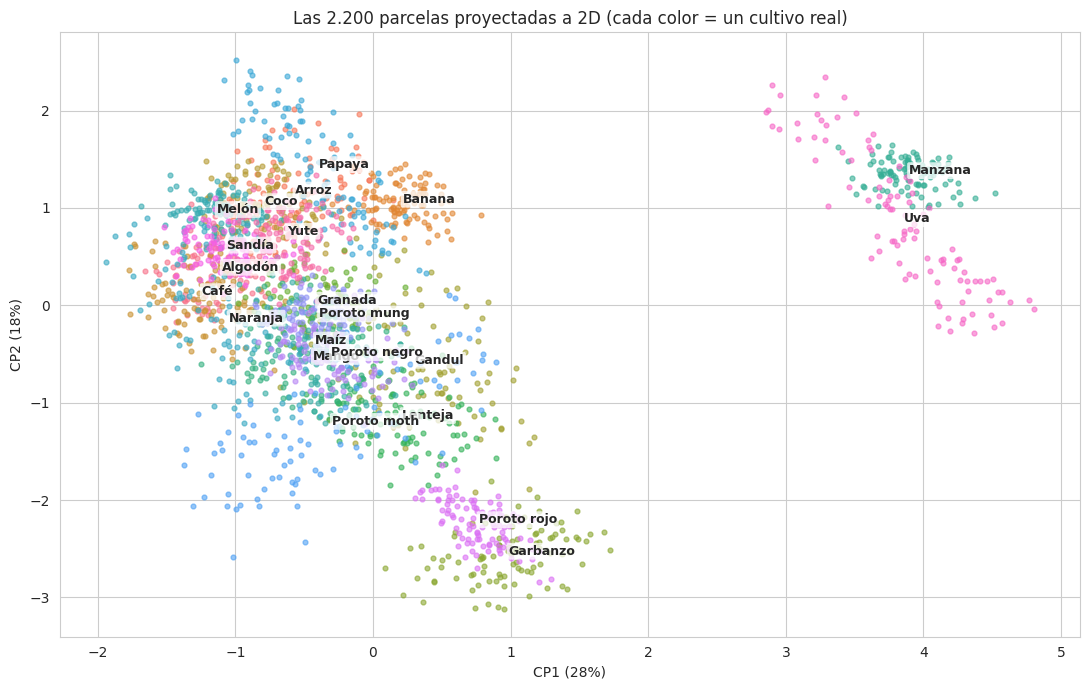

In [21]:
Z = PCA(n_components=2).fit_transform(Xs)
paleta = sns.color_palette("husl", 22); orden = sorted(set(y_real))
fig, ax = plt.subplots(figsize=(11, 7))
for i, c in enumerate(orden):
    m = y_real == c; ax.scatter(Z[m, 0], Z[m, 1], s=12, color=paleta[i], alpha=.6)
    ax.text(Z[m, 0].mean(), Z[m, 1].mean(), c, fontsize=9, weight="bold",
            bbox=dict(boxstyle="round,pad=.15", fc="white", alpha=.75, lw=0))
ax.set_xlabel(f"CP1 ({ev[0]:.0%})"); ax.set_ylabel(f"CP2 ({ev[1]:.0%})")
ax.set_title("Las 2.200 parcelas proyectadas a 2D (cada color = un cultivo real)")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>Aun en solo 2 dimensiones, <b>varios cultivos forman islas bien definidas</b> (los que tienen condiciones muy particulares) y otros se solapan en el centro. Al sumar las otras dimensiones esos solapes se separan, y por eso la clasificación supervisada llega al ~99 %.</div>

### 6.2 · K-Means — agrupar por parecido

<div style="border-left:6px solid #444;background:#f7f7f7;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🧩 Ficha del algoritmo</b><br><b>Idea:</b> elige <i>k</i> "centros" y asigna cada parcela al más cercano; luego mueve cada centro al promedio de su grupo y repite hasta estabilizar.<br><b>Parámetro:</b> <code>k</code> (cuántos grupos) — hay que decidirlo nosotros.<br><b>Qué muestra:</b> si los datos tienen grupos naturales y cuántos.</div>

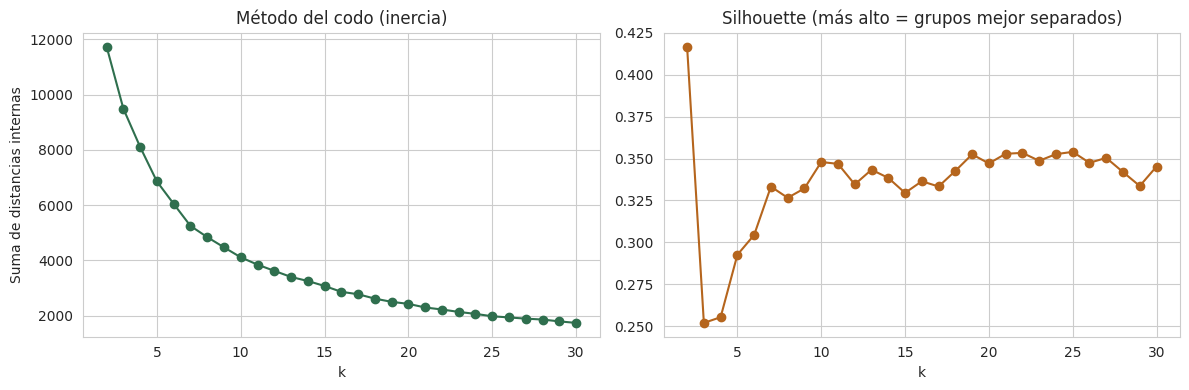

k con mejor silhouette: 2 (0.417)


In [22]:
ks = range(2, 31)
inercia, silu = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Xs)
    inercia.append(km.inertia_); silu.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercia, "o-", color="#2f6f4e"); ax[0].set_title("Método del codo (inercia)")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Suma de distancias internas")
ax[1].plot(ks, silu, "o-", color="#b5651d"); ax[1].set_title("Silhouette (más alto = grupos mejor separados)")
ax[1].set_xlabel("k"); plt.tight_layout(); plt.show()
print("k con mejor silhouette:", list(ks)[int(np.argmax(silu))], f"({max(silu):.3f})")

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br><b>¿Cómo elegir k sin saber la respuesta?</b> Dos pistas: (1) el <b>codo</b>: la inercia siempre baja al agregar grupos, pero hay un punto donde deja de bajar mucho; (2) el <b>silhouette</b>: mide qué tan bien separado está cada punto de los otros grupos (de −1 a 1).
<br>Acá las dos pistas <b>no dan un número claro</b>: no hay un codo nítido, y el silhouette se maximiza en <b>k = 2</b> (≈0,42), o sea, una separación grande entre dos "macro-grupos" que no refleja los 22 cultivos. Eso es información: la estructura es <b>jerárquica</b> (grupos dentro de grupos) y no hay un único k "natural". Por eso usamos k = 22 sabiendo la respuesta, solo para <i>comparar</i> con la realidad.</div>

Comparación con los cultivos reales (k=22):
  Índice de Rand ajustado (ARI)    : 0.676   (0 = azar, 1 = coinciden exacto)
  Información mutua normalizada    : 0.845
  Homogeneidad (¿cada grupo es de un solo cultivo?): 0.831
  Completitud  (¿cada cultivo cae en un solo grupo?): 0.860


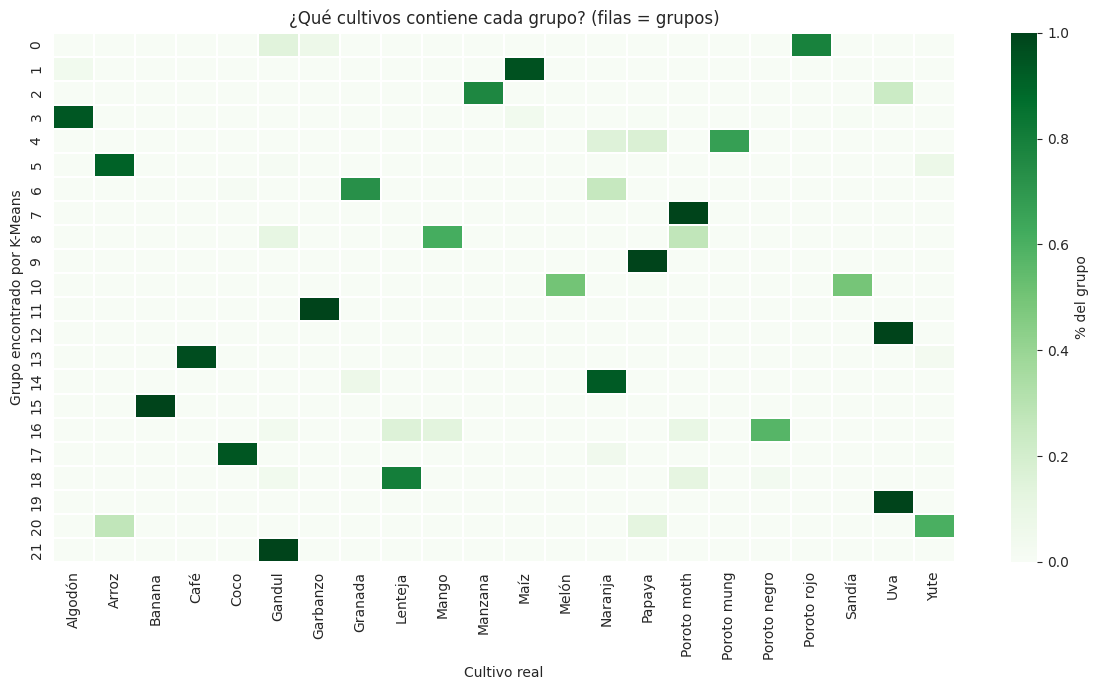

Pureza promedio de los grupos: 85.0%  | grupos 100 % puros: 7 de 22


In [23]:
km22 = KMeans(22, n_init=20, random_state=SEED).fit(Xs)       # k=22 porque SABEMOS que hay 22 cultivos
etq = km22.labels_

print("Comparación con los cultivos reales (k=22):")
print(f"  Índice de Rand ajustado (ARI)    : {adjusted_rand_score(y_real, etq):.3f}   (0 = azar, 1 = coinciden exacto)")
print(f"  Información mutua normalizada    : {normalized_mutual_info_score(y_real, etq):.3f}")
print(f"  Homogeneidad (¿cada grupo es de un solo cultivo?): {homogeneity_score(y_real, etq):.3f}")
print(f"  Completitud  (¿cada cultivo cae en un solo grupo?): {completeness_score(y_real, etq):.3f}")

ct = pd.crosstab(etq, y_real, normalize="index")
plt.figure(figsize=(12, 7)); sns.heatmap(ct, cmap="Greens", cbar_kws={"label": "% del grupo"}, linewidths=.2)
plt.xlabel("Cultivo real"); plt.ylabel("Grupo encontrado por K-Means")
plt.title("¿Qué cultivos contiene cada grupo? (filas = grupos)"); plt.tight_layout(); plt.show()
pureza = ct.max(axis=1); print(f"Pureza promedio de los grupos: {pureza.mean():.1%}  | grupos 100 % puros: {(pureza > .99).sum()} de 22")

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>
<ul>
<li>Sin ver ninguna etiqueta, K-Means <b>recupera buena parte de la estructura real</b>: ARI ≈ 0,68, pureza promedio ≈ 85 % y <b>7 de los 22 grupos son 100 % de un solo cultivo</b> (filas con una sola celda verde oscura en el mapa).</li>
<li>Pero <b>no es perfecto</b>: <i>melón y sandía</i> quedan en un mismo grupo, la <i>uva</i> se parte en dos grupos y el <i>arroz</i> comparte grupo con yute y papaya. K-Means busca bolas redondas del mismo tamaño y algunos cultivos tienen formas alargadas o se solapan.</li>
<li>Diferencia clave con la parte supervisada: acá el algoritmo <b>descubre</b> (≈ lo que se ve con el ARI y la pureza) pero no <b>decide</b> con la precisión del supervisado, que tuvo las respuestas a la vista.</li>
</ul></div>

### 6.3 · Clustering jerárquico — el árbol genealógico de los cultivos

<div style="border-left:6px solid #444;background:#f7f7f7;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🧩 Ficha del algoritmo</b><br><b>Idea:</b> empieza con cada elemento solo y va fusionando los dos más parecidos, una y otra vez, hasta formar un único grupo. El resultado es un <b>dendrograma</b> (árbol).<br><b>Parámetro:</b> método de enlace (usamos <i>Ward</i>) y dónde "cortar" el árbol.<br><b>Qué muestra:</b> qué cultivos son "parientes" y a qué distancia se parecen. <b>No hace falta decidir k de antemano.</b></div>

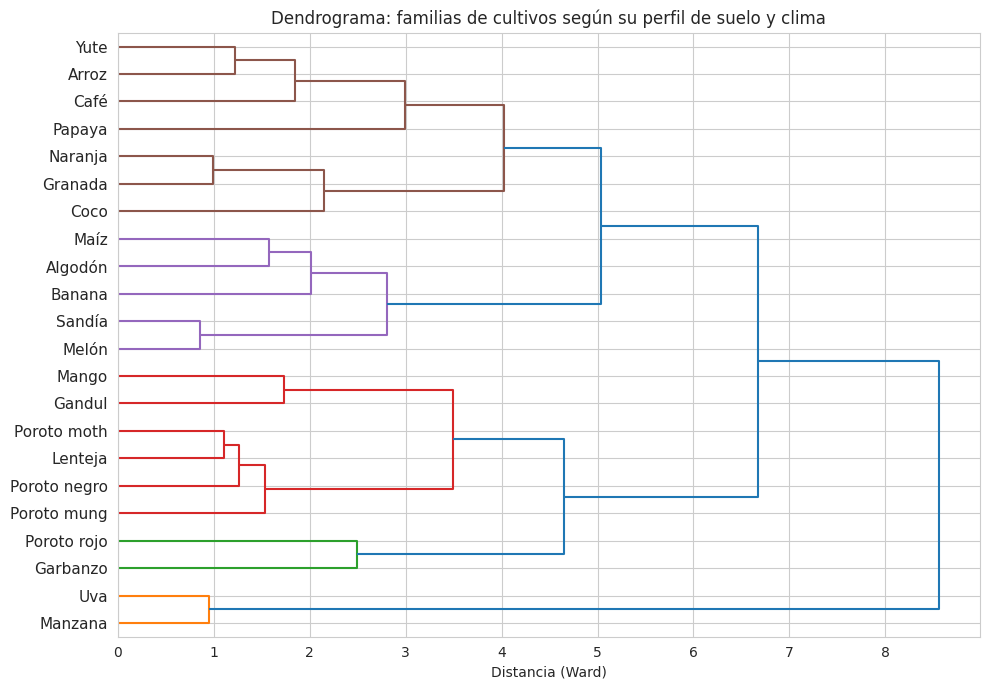

Familia 1: Manzana, Uva
Familia 2: Garbanzo, Poroto rojo
Familia 3: Gandul, Lenteja, Mango, Poroto moth, Poroto mung, Poroto negro
Familia 4: Algodón, Banana, Maíz, Melón, Sandía
Familia 5: Arroz, Café, Coco, Granada, Naranja, Papaya, Yute


In [24]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
centroides = pd.DataFrame(Xs, columns=VARS).groupby(y_real).mean()      # perfil promedio de cada cultivo
L = linkage(centroides, method="ward")

fig, ax = plt.subplots(figsize=(10, 7))
dendrogram(L, labels=centroides.index, orientation="right", leaf_font_size=11, color_threshold=4.4, ax=ax)
ax.set_title("Dendrograma: familias de cultivos según su perfil de suelo y clima"); ax.set_xlabel("Distancia (Ward)")
plt.tight_layout(); plt.show()

familias = fcluster(L, t=5, criterion="maxclust")
for f in sorted(set(familias)):
    print(f"Familia {f}:", ", ".join(centroides.index[familias == f]))

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>El árbol agrupa cultivos con <b>necesidades ambientales parecidas</b>. En nuestra corrida: <i>arroz, yute, coco, café, papaya, naranja y granada</i> quedan juntos (perfiles de clima cálido y húmedo); <i>manzana y uva</i> forman su propio grupo; <i>garbanzo y poroto rojo</i> van juntos; y <i>poroto negro, lenteja, poroto moth, poroto mung y gandul</i> (legumbres) forman otra rama, junto con el mango. Para un asesor técnico esto es oro: <b>si el cultivo recomendado no es viable, sus "primos" cercanos del árbol son las mejores alternativas</b>.</div>

In [25]:
agg = AgglomerativeClustering(n_clusters=22, linkage="ward").fit(Xs)
print(f"Jerárquico (22 grupos, sobre las 2.200 parcelas) · ARI vs. cultivos reales: {adjusted_rand_score(y_real, agg.labels_):.3f}")
print(f"K-Means (22 grupos)                             · ARI vs. cultivos reales: {adjusted_rand_score(y_real, etq):.3f}")

Jerárquico (22 grupos, sobre las 2.200 parcelas) · ARI vs. cultivos reales: 0.699
K-Means (22 grupos)                             · ARI vs. cultivos reales: 0.676


### 6.4 · Mezcla gaussiana (clustering probabilístico) — pertenecer "en porcentajes"

<div style="border-left:6px solid #444;background:#f7f7f7;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🧩 Ficha del algoritmo</b><br><b>Idea:</b> en vez de asignar cada parcela a <i>un solo</i> grupo, modela cada grupo como una "nube" con forma de elipse y calcula la <b>probabilidad</b> de pertenecer a cada una.<br><b>Parámetro:</b> cantidad de componentes (se puede elegir con el criterio <b>BIC</b>).<br><b>Qué muestra:</b> qué parcelas son <b>ambiguas</b> (60 % de un grupo / 40 % de otro), algo que K-Means no puede decir.</div>

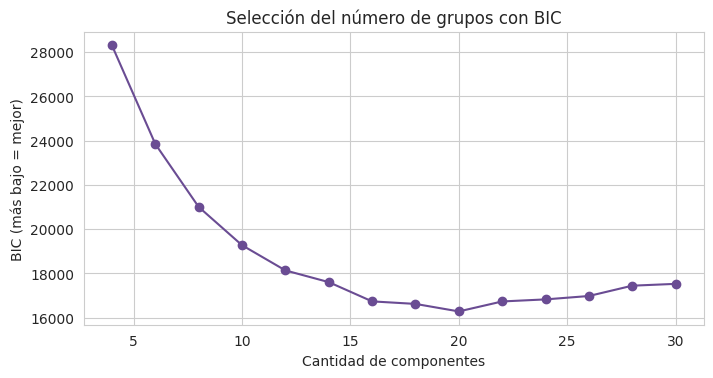

Mejor BIC con k = 20



GMM (22 componentes) · ARI vs. cultivos reales: 0.936
Parcelas 'ambiguas' (ninguna probabilidad llega al 90 %): 45 de 2200 (2.0%)


In [26]:
ks_g = range(4, 31, 2)
bic = [GaussianMixture(k, covariance_type="full", random_state=SEED, n_init=2).fit(Xs).bic(Xs) for k in ks_g]
plt.figure(figsize=(8, 3.8)); plt.plot(list(ks_g), bic, "o-", color="#6a4c93")
plt.xlabel("Cantidad de componentes"); plt.ylabel("BIC (más bajo = mejor)"); plt.title("Selección del número de grupos con BIC")
plt.show()
print("Mejor BIC con k =", list(ks_g)[int(np.argmin(bic))])

gmm = GaussianMixture(22, covariance_type="full", random_state=SEED, n_init=3).fit(Xs)
pg = gmm.predict_proba(Xs); etq_g = pg.argmax(1)
print(f"\nGMM (22 componentes) · ARI vs. cultivos reales: {adjusted_rand_score(y_real, etq_g):.3f}")
ambiguas = (pg.max(1) < 0.90).sum()
print(f"Parcelas 'ambiguas' (ninguna probabilidad llega al 90 %): {ambiguas} de {len(pg)} ({ambiguas/len(pg):.1%})")

In [27]:
# Ejemplo concreto: la parcela más ambigua
i = int(np.argsort(pg.max(1))[0])
top = np.argsort(-pg[i])[:3]
mapa_cult = pd.Series(y_real).groupby(etq_g).agg(lambda s: s.value_counts().index[0])   # cultivo dominante de cada componente
print(f"Cultivo real de esta parcela: {y_real[i]}\n")
for t in top:
    print(f"  Componente {t:2d} (dominada por '{mapa_cult.get(t, '—')}'): {pg[i, t]:.1%}")

Cultivo real de esta parcela: Arroz

  Componente 13 (dominada por 'Arroz'): 50.8%
  Componente  7 (dominada por 'Yute'): 49.2%
  Componente 21 (dominada por 'Café'): 0.0%


<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>La mayoría de las parcelas tiene una pertenencia <b>casi segura</b> y solo el ~2 % son <b>ambiguas</b> (en la frontera entre dos cultivos). Dos hallazgos: (1) la mezcla gaussiana recupera los cultivos <b>mucho mejor que K-Means</b> (ARI ≈ 0,94 contra ≈ 0,68) porque cada cultivo es una "nube" elíptica de tamaño y forma propios, y K-Means solo sabe de bolas redondas; (2) en nuestra corrida, la parcela más ambigua es justamente una <b>arroz/yute</b> (≈ 51 % vs 49 %), la misma pareja que se confundió en la matriz de confusión y que el dendrograma pone en la misma familia: <b>tres algoritmos distintos cuentan la misma historia</b>.</div>

<div style="border-left:6px solid #6a4c93;background:#f5f0fa;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>💡 Para aprender</b><br>
<b>Resumen de la Parte 6 — qué muestra cada algoritmo no supervisado:</b>
<table style="border-collapse:collapse;font-size:15px;">
<tr><td><b>PCA</b></td><td>&nbsp;→ cuánta información hay y cómo se reparte; permite <i>ver</i> los datos.</td></tr>
<tr><td><b>K-Means</b></td><td>&nbsp;→ si existen grupos naturales y cuánto coinciden con la realidad.</td></tr>
<tr><td><b>Jerárquico</b></td><td>&nbsp;→ el parentesco entre cultivos (familias y alternativas cercanas).</td></tr>
<tr><td><b>Mezcla gaussiana</b></td><td>&nbsp;→ la incertidumbre: qué parcelas están en zona de frontera.</td></tr>
</table></div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 7</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Regiones agrícolas de India</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Clustering sobre el dato real (Dataset B): ¿qué "personalidad" productiva tiene cada estado?</div></div>

<div style="border-left:6px solid #2f6f4e;background:#f1f8f3;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🗣️ En criollo</b><br>Ahora usamos el no supervisado sobre el <b>dato oficial</b>: para cada estado calculamos <b>qué porcentaje de su superficie sembrada</b> corresponde a cada cultivo (arroz, trigo, coco, algodón…) y agrupamos los estados parecidos. Usamos <b>proporciones de superficie</b> (no producción) a propósito: así las <b>unidades inconsistentes</b> del dataset (coco contado en unidades, no toneladas) no distorsionan el resultado.</div>

In [28]:
mezcla = d.groupby(["Estado", "Cultivo"]).Area_ha.sum().unstack(fill_value=0)
mezcla = mezcla.div(mezcla.sum(axis=1), axis=0)                  # proporción de superficie por cultivo
top15 = mezcla.mean().sort_values(ascending=False).head(15).index
M = mezcla[top15]
print("Cultivos que definen la mezcla:", ", ".join(top15))

ks_e = range(2, 9)
sil_e = {k: silhouette_score(M, KMeans(k, n_init=10, random_state=SEED).fit_predict(M)) for k in ks_e}
display(pd.Series(sil_e, name="silhouette").to_frame().T)
K_E = max(sil_e, key=sil_e.get)
print("k elegido (mejor silhouette):", K_E)
km_e = KMeans(K_E, n_init=10, random_state=SEED).fit(M)

for g in range(K_E):
    est = list(M.index[km_e.labels_ == g]); perfil = M[km_e.labels_ == g].mean().sort_values(ascending=False).head(3)
    print(f"\n🟢 Región {g+1} ({len(est)} estados): " + ", ".join(est))
    print("   Perfil:", ", ".join(f"{c} {v:.0%}" for c, v in perfil.items()))

Cultivos que definen la mezcla: Arroz, Trigo, Maíz, Coco, Algodón, Colza y mostaza, Maní, Mijo perla, Sorgo, Caña de azúcar, Soja, Garbanzo, Urad, Gandul, Castaña de cajú


,2,3,4,5,6,7,8
silhouette,0.382,0.387,0.431,0.371,0.400,0.390,0.354


k elegido (mejor silhouette): 4

🟢 Región 1 (8 estados): Bihar, Chandigarh, Haryana, Himachal Pradesh, Jammu y Cachemira, Punjab, Uttar Pradesh, Uttarakhand
   Perfil: Trigo 42%, Arroz 25%, Maíz 13%

🟢 Región 2 (14 estados): Arunachal Pradesh, Assam, Bengala Occidental, Chhattisgarh, Dadra y Nagar Haveli, Goa, Jharkhand, Manipur, Meghalaya, Mizoram, Nagaland, Odisha, Puducherry, Tripura
   Perfil: Arroz 69%, Maíz 5%, Castaña de cajú 2%

🟢 Región 3 (9 estados): Andhra Pradesh, Gujarat, Karnataka, Madhya Pradesh, Maharashtra, Rajasthan, Sikkim, Tamil Nadu, Telangana
   Perfil: Arroz 17%, Maíz 10%, Algodón 8%

🟢 Región 4 (2 estados): Islas Andamán y Nicobar, Kerala
   Perfil: Coco 53%, Arroz 19%, Castaña de cajú 3%


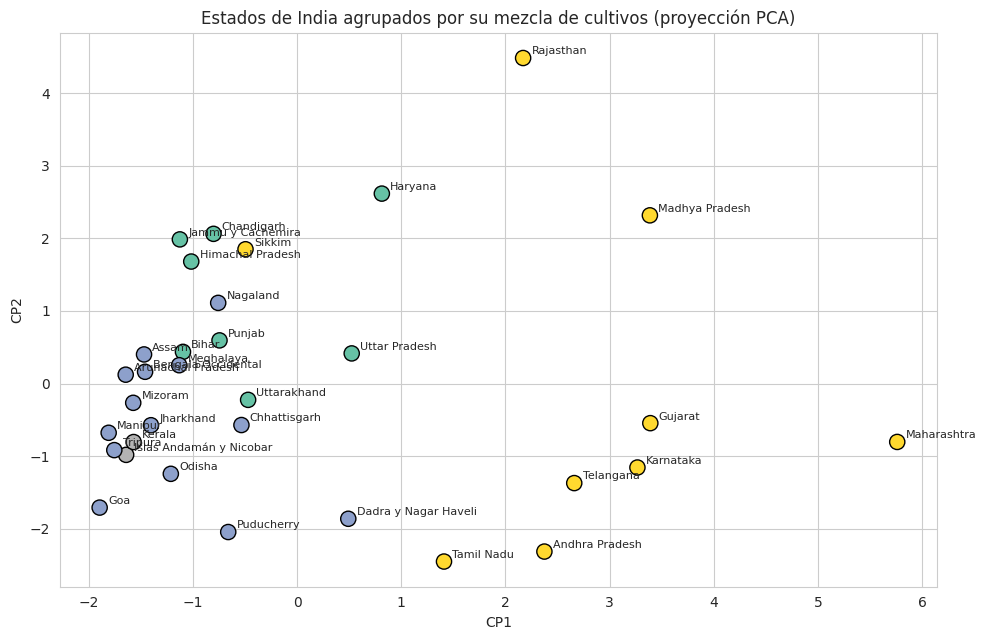

In [29]:
Z_e = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(M))
fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(Z_e[:, 0], Z_e[:, 1], c=km_e.labels_, cmap="Set2", s=120, edgecolor="k")
for i, est in enumerate(M.index): ax.text(Z_e[i, 0] + .08, Z_e[i, 1] + .05, est, fontsize=8)
ax.set_title("Estados de India agrupados por su mezcla de cultivos (proyección PCA)"); ax.set_xlabel("CP1"); ax.set_ylabel("CP2")
plt.tight_layout(); plt.show()

<div style="border-left:6px solid #3b6ea5;background:#eaf3fb;padding:12px 18px;margin:12px 0;border-radius:0 8px 8px 0;font-family:'Segoe UI',system-ui,sans-serif;font-size:15.5px;line-height:1.6;color:#14181a;"><b>🔎 Qué nos muestra</b><br>El algoritmo, <b>sin saber nada de geografía</b>, reconstruye 4 regiones agrícolas reconocibles: una <b>región arrocera</b> (≈ 69 % de la superficie en arroz: este y noreste), la <b>franja triguera-arrocera del norte</b> (trigo ≈ 42 %), una región <b>diversificada de secano</b> (algodón, maíz, arroz: oeste y sur de la península) y la <b>costa cocotera</b> (Kerala y Andamán, coco ≈ 53 %). Los estados de frontera conviene revisarlos con un experto: <b>Madhya Pradesh</b> (su perfil está justo en el límite entre la franja del trigo y la zona diversificada; al traducir los nombres cambió el orden de las columnas y pasó de una región a la otra) y <b>Sikkim</b> (muy pequeño). Es una lección: <b>los grupos de K-Means tienen bordes borrosos</b> y los estados del límite pueden cambiar de grupo con cambios mínimos en el cálculo. Es un ejemplo de que el no supervisado <b>descubre conocimiento</b> que luego un experto puede nombrar e interpretar.
<br><br>Y es un resultado <b>real</b>: depende de que el Dataset B esté bien limpio. Sin normalizar <code>Paddy</code>/<code>Rice</code> ni quitar las filas de totales, la mezcla de cada estado estaría <b>distorsionada</b> (ver Taller 2b).</div>

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 8</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Algoritmos de la consigna: qué usamos y por qué</div><div style="font-family:'Segoe UI',system-ui,sans-serif;font-size:16px;color:#3d4f47;margin-top:4px;">Justificación de cada elección</div></div>

### Supervisados
| Algoritmo de la consigna | ¿Usado? | Dónde / por qué |
|---|---|---|
| Naïve Bayes | ✅ | Parte 2 · *baseline* simple y muy rápido; empata arriba |
| Regresión lineal | ✅ | Parte 5 · rendimiento (variable continua); permite leer tendencias |
| Regresión no lineal | ✅ (vía Random Forest / Gradient Boosting) | Parte 5 · capturan relaciones no lineales sin fijar una fórmula |
| Regresión logística | ✅ | Parte 2 · clasificación; el modelo lineal "de referencia" |
| Regresión polinomial | ✅ | Parte 5 · grado 2; no mejora a la lineal, y ese hallazgo también es resultado |
| SVM | ✅ | Parte 2 · frontera de máximo margen; ajustado con `C` y `gamma` |
| K-Vecino más cercano | ✅ | Parte 2 · ajustado con `k` |
| Árbol de decisión | ✅ | Parte 2 · interpretabilidad y demostración de *overfitting* |
| Random Forest | ✅ | Parte 2, 3, 4 y 5 · modelo final de recomendación |

### No supervisados
| Algoritmo de la consigna | ¿Usado? | Dónde / por qué |
|---|---|---|
| Clustering exclusivo | ✅ K-Means | Parte 6 y 7 |
| Clustering superpuesto / probabilístico | ✅ Mezcla gaussiana | Parte 6.4 · cada parcela pertenece "en porcentajes" |
| Clustering jerárquico | ✅ | Parte 6.3 · dendrograma de cultivos |
| PCA | ✅ | Parte 6.1 y 7 · visualización y carga de variables (no se aplica al modelo; ver decisión de la Etapa 1) |
| SVD | ➖ | PCA se calcula internamente mediante SVD; conceptualmente cubierto |
| Apriori | ❌ | Requiere datos de "canasta" (transacciones); este dataset no tiene esa forma |
| Autocodificadores | ❌ | Redes neuronales: con 7 variables y 2.200 filas no aportan sobre PCA y sacrifican interpretabilidad |

<div style="border-left:8px solid #2f6f4e;background:#f4f8f5;padding:16px 22px;margin:28px 0 12px 0;border-radius:0 8px 8px 0;"><div style="font-family:Georgia,serif;font-size:13px;letter-spacing:2px;color:#a04e14;font-weight:700;text-transform:uppercase;">Parte 9</div><div style="font-family:Georgia,serif;font-size:26px;font-weight:700;color:#143026;">Conclusiones y limitaciones</div></div>

### ✅ Qué aprendimos
1. **Supervisado:** los 6 algoritmos superan el 96 % frente al 4,5 % del azar; **Naïve Bayes y Random Forest empatan**. Se eligió **Random Forest** como modelo final porque da *probabilidades* (para el Top-3), tiene importancia de variables incorporada y es estable; no porque sea "el ganador" de forma estadísticamente significativa.
2. **Ninguna variable domina** en la clasificación: sola, la mejor llega a ~30 %; sacar cualquiera casi no cambia el resultado. **La información está en la combinación.**
3. **Sí hay una variable dominante en la regresión** (`Cultivo`): da un R² alto que esconde el resto. Al modelar *dentro de cada cultivo* aparecen el estado, la temporada y la superficie, y el R² real es moderado.
4. **No supervisado:** el PCA muestra que la información está repartida (5 de 7 componentes para ~88 %); K-Means recupera parte de los cultivos reales **sin ver etiquetas** (ARI ≈ 0,68); la **mezcla gaussiana lo hace mucho mejor (ARI ≈ 0,94)** y marca las parcelas de frontera; el jerárquico revela "familias" de cultivos.
5. **Sobre datos reales sucios:** el Dataset B solo sirvió para modelar y agrupar después de limpiarlo (ver Taller 2b).

### ⚠️ Limitaciones (para decir en la presentación)
- **El Dataset A es demasiado perfecto**: 100 casos exactos por clase y cultivos muy separados. El ~99 % **no se trasladaría** tal cual al campo.
- **Geografía:** datos de India. No debe extrapolarse a otras regiones (p. ej., San Luis) sin validación local.
- **Sin precios ni costos:** la recomendación es agronómica, no económica.
- **R² moderado dentro de un cultivo:** faltan variables (riego, fertilización, clima de la campaña).
- **Los árboles no extrapolan** en el tiempo.

### 🚀 Próximos pasos
Validar con datos locales, sumar precio y costo, incorporar clima de la campaña al modelo de rendimiento, y evaluar la calibración de las probabilidades del Top-3.